PLOT DV/THEORY

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob

Seeds :  [0]
Shape xi_files :  (2600, 10)
Shape sxi_files :  (2600, 10)
Shape r_files :  (2600, 10)
Shape d_files :  (2600, 10)
Shape th_xi_files :  (25, 10)
Shape th_r_files :  (25, 10)
0
104
567.199999999999


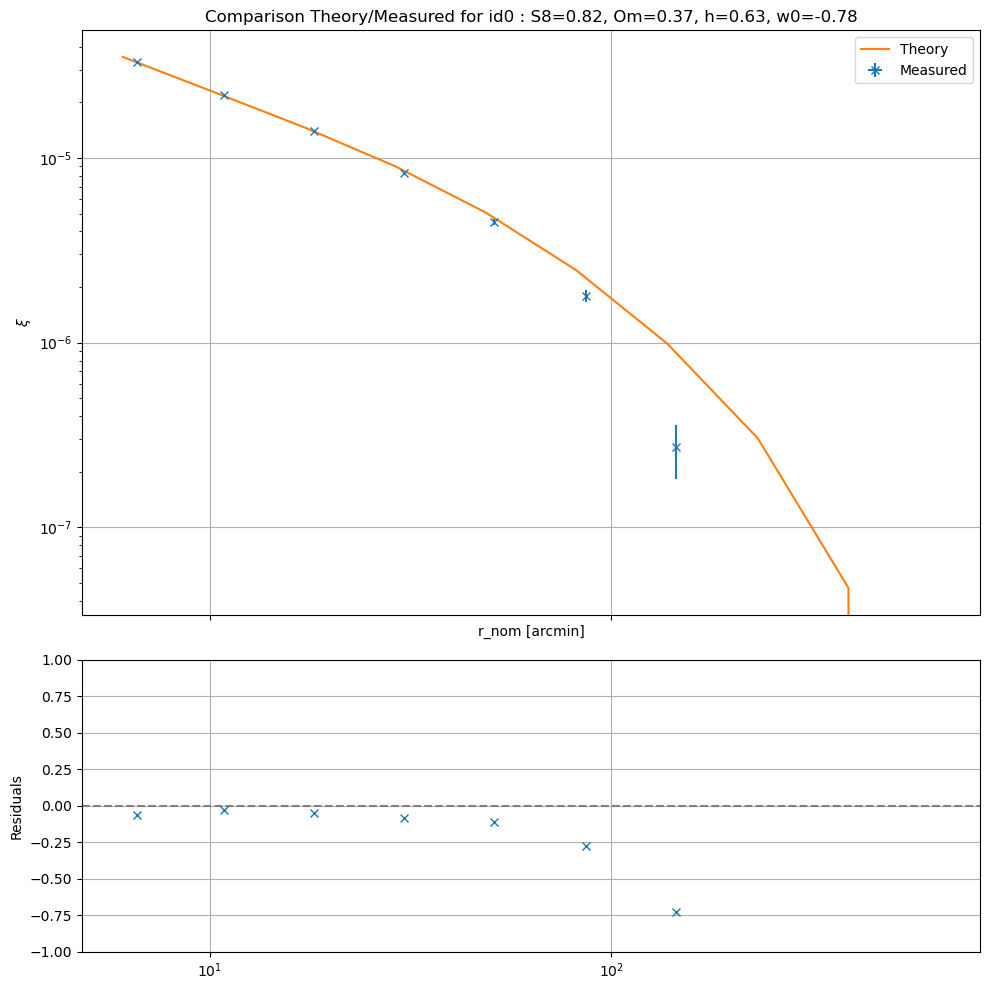

567.199999999999
567.199999999999
567.199999999999
567.199999999999
567.199999999999


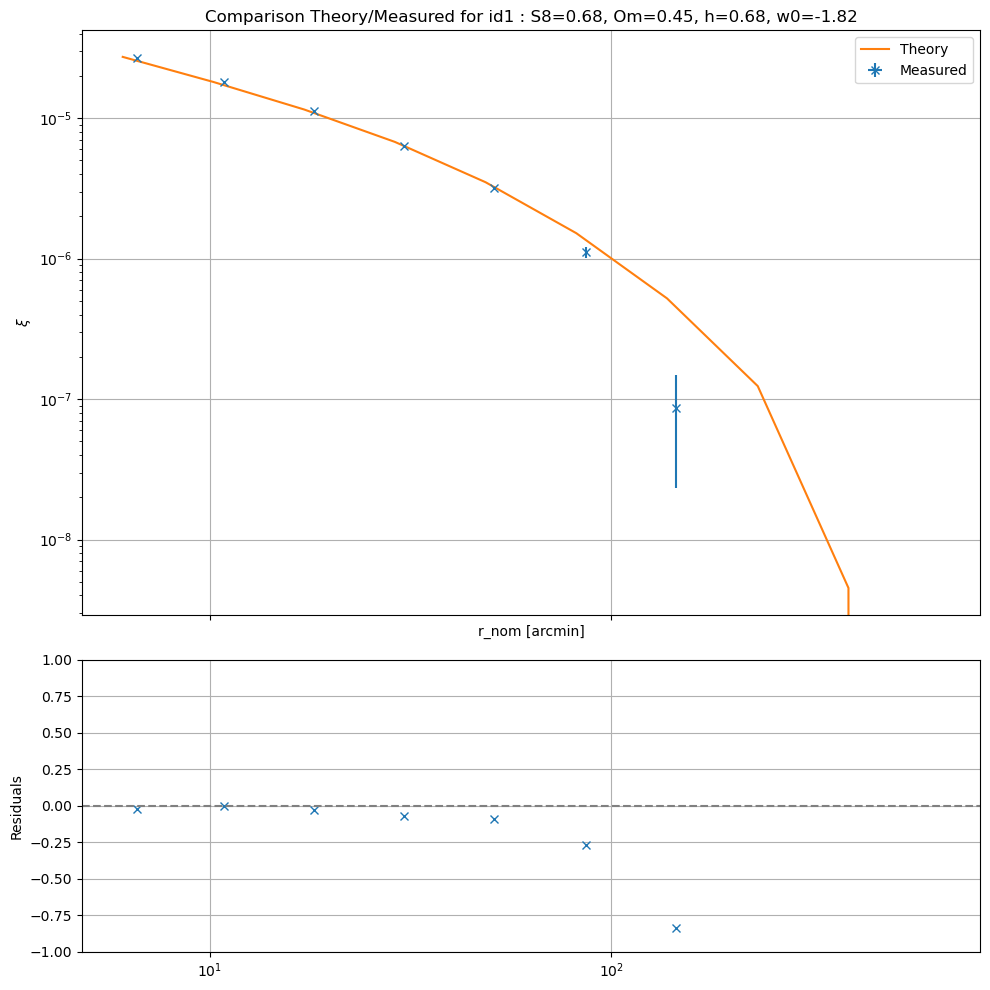

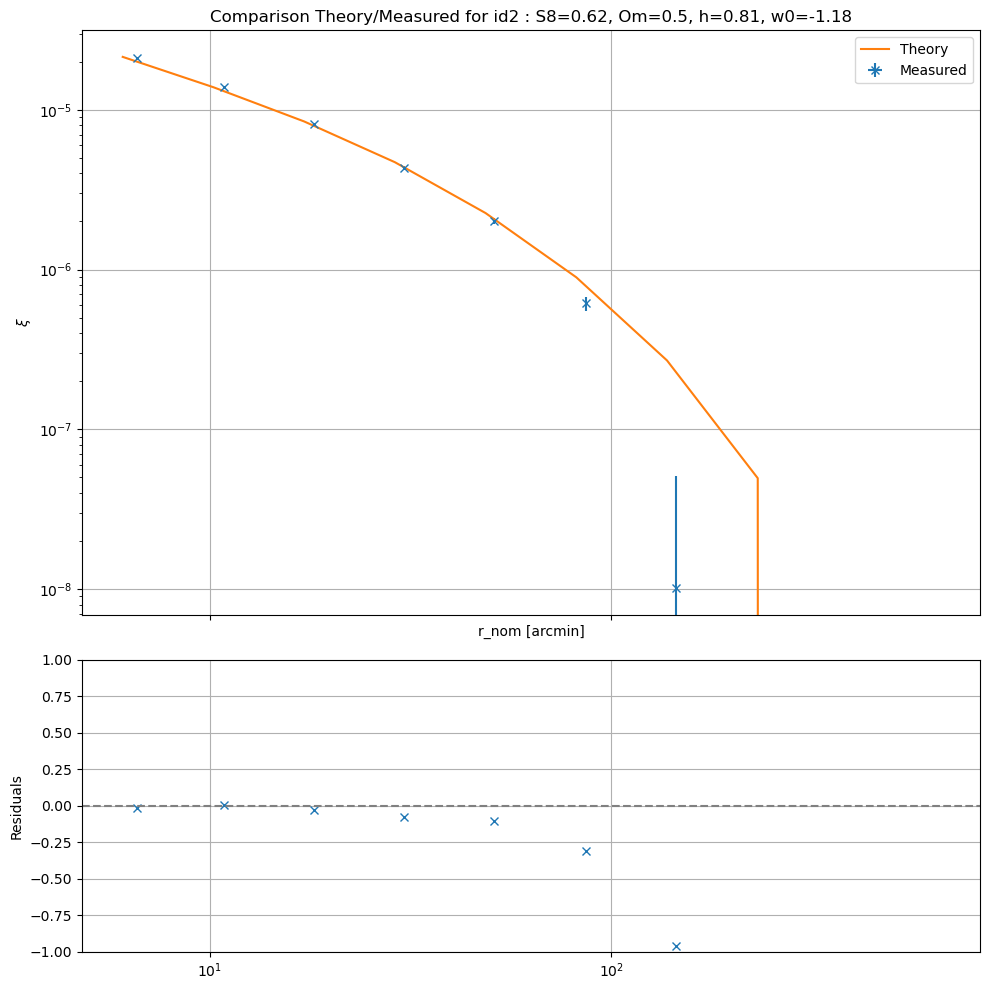

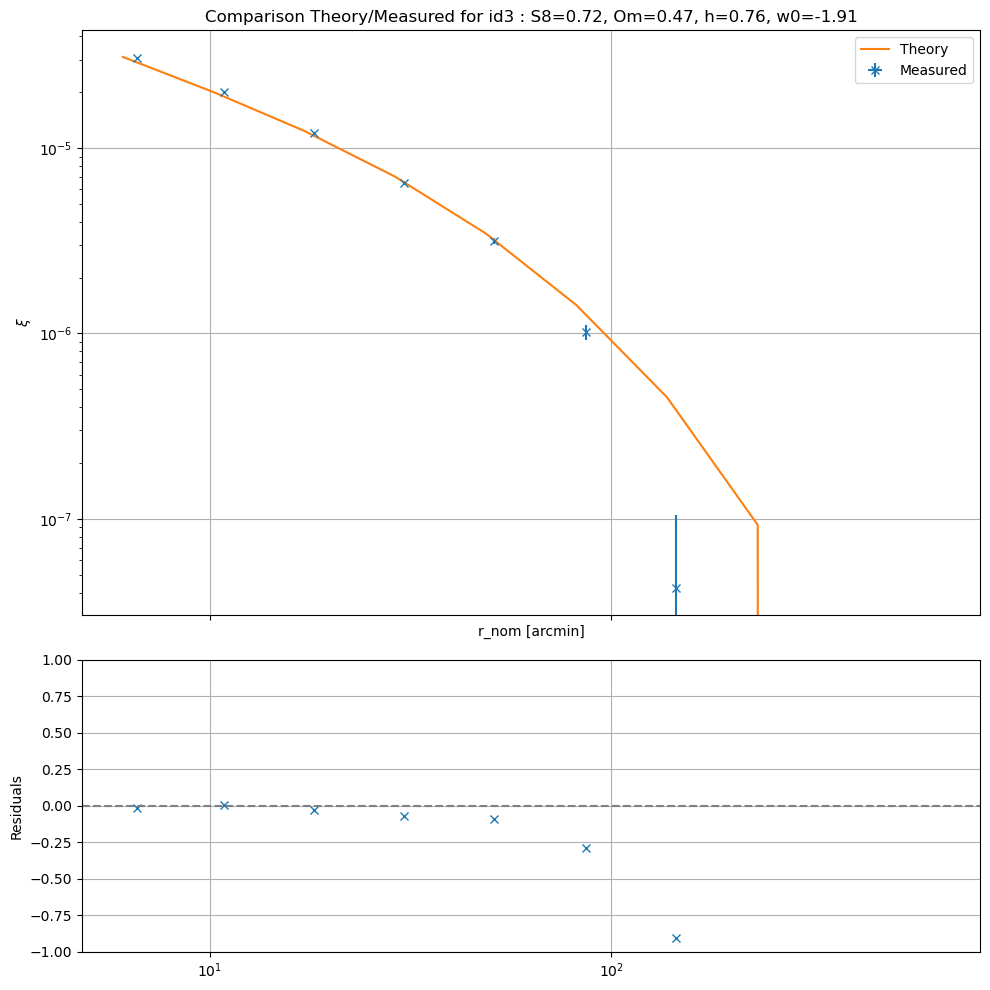

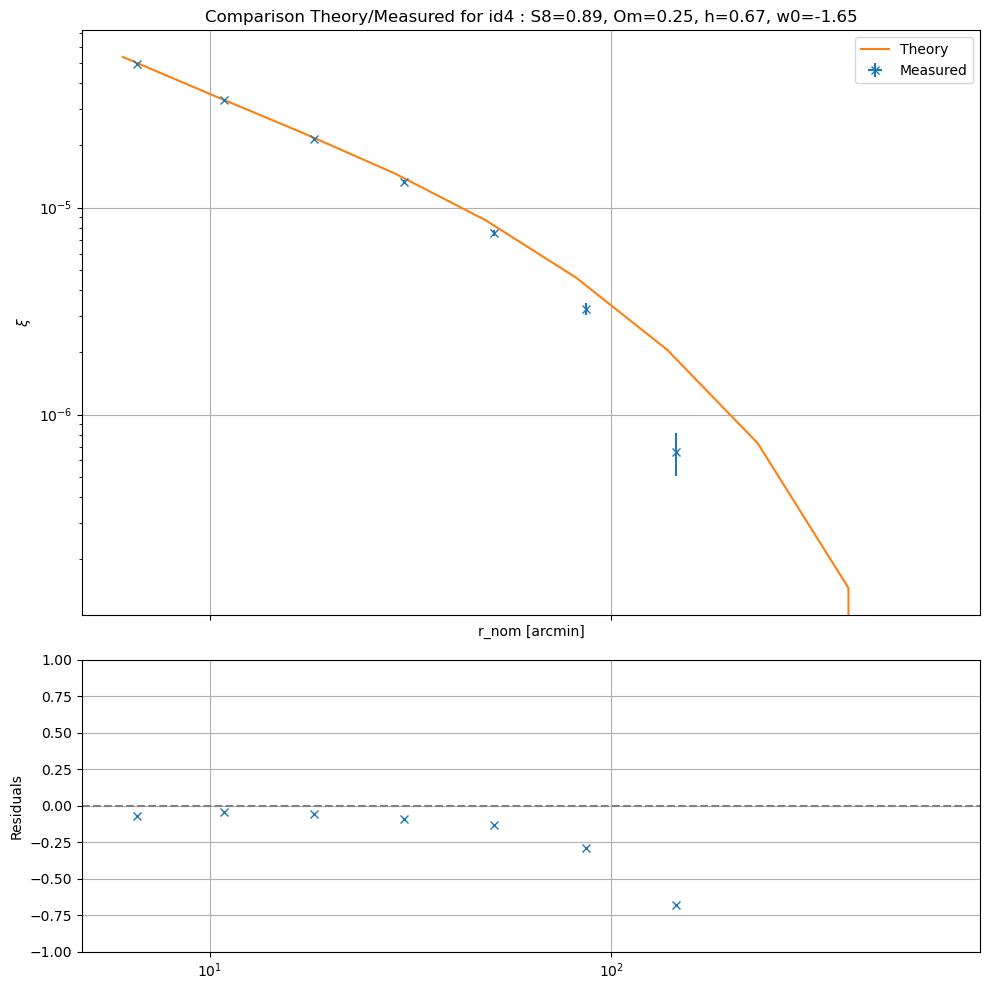

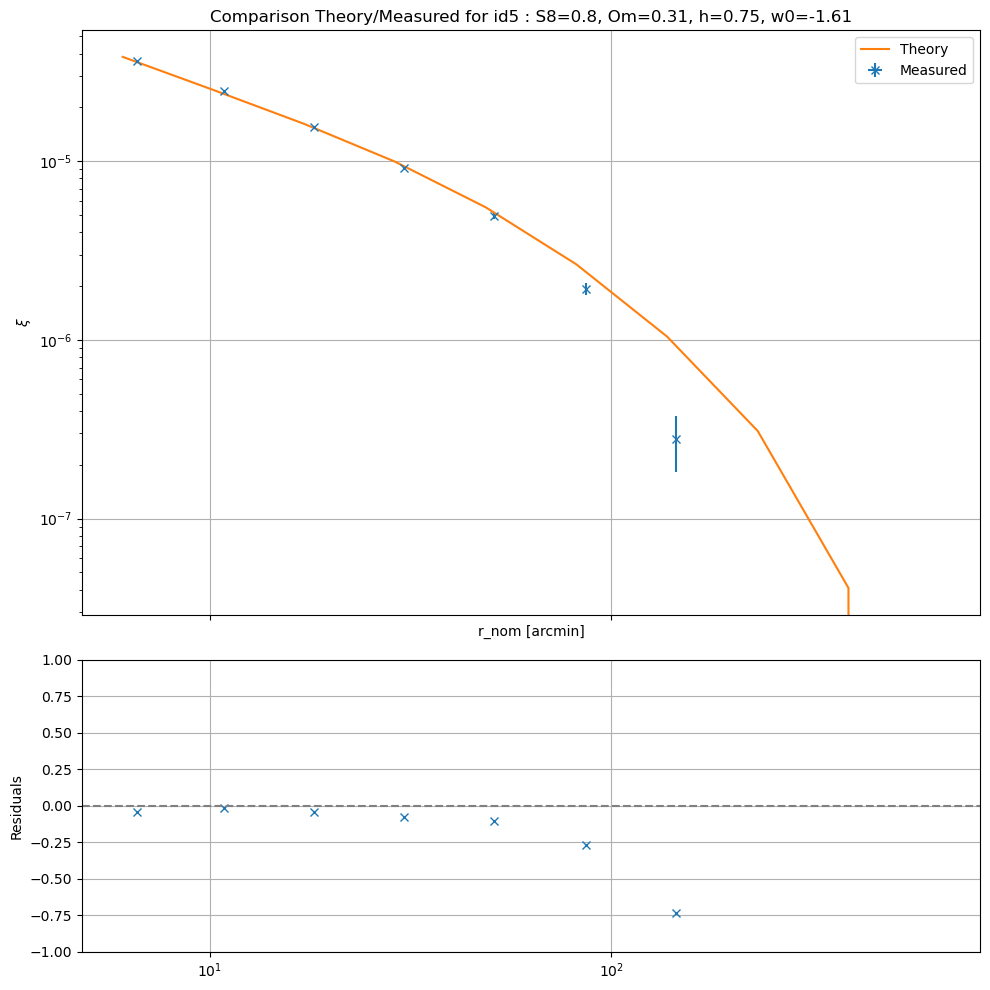

567.199999999999
567.199999999999
567.199999999999
567.199999999999
567.199999999999


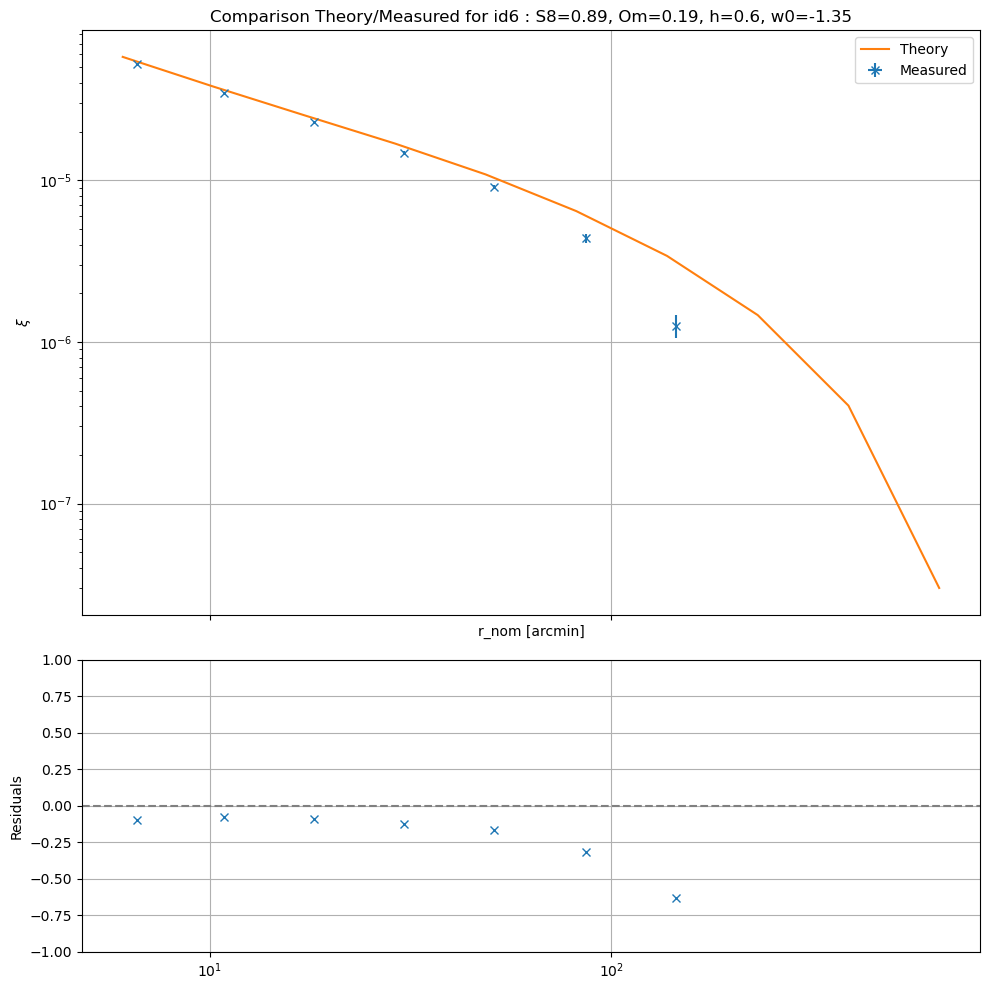

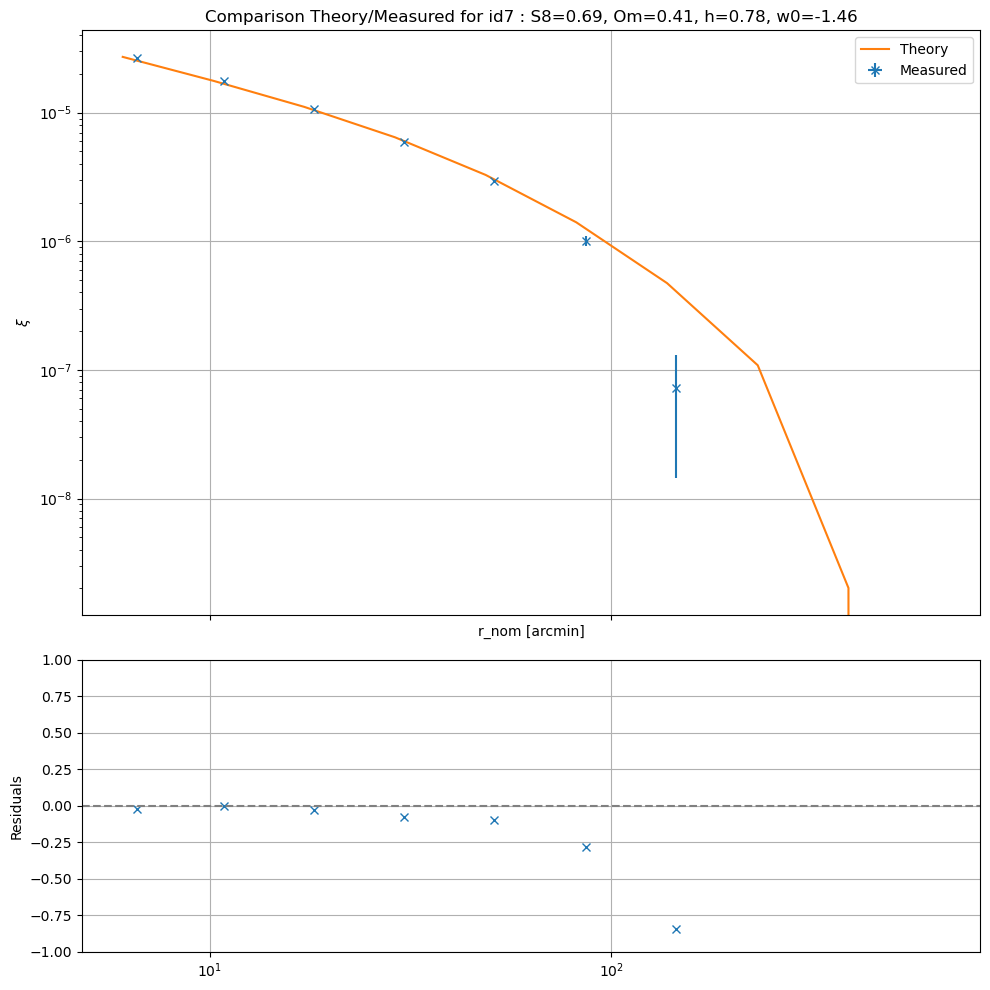

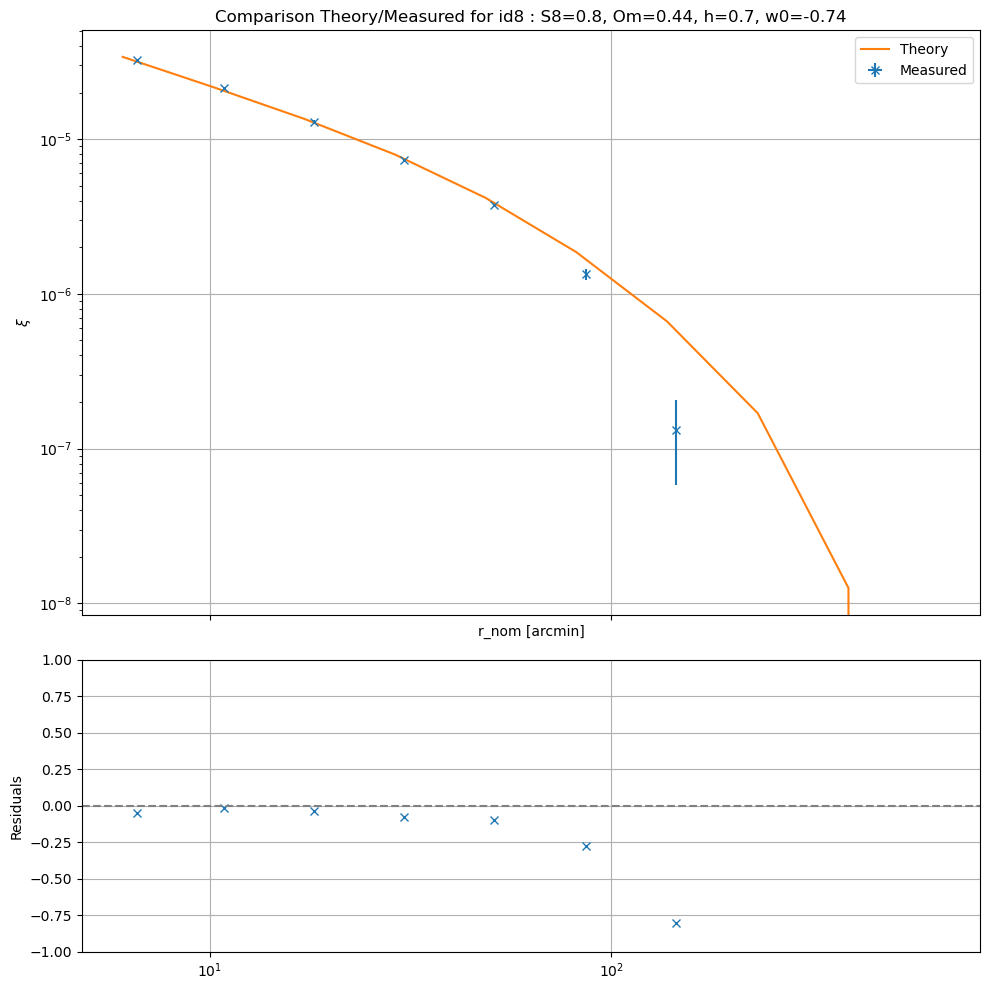

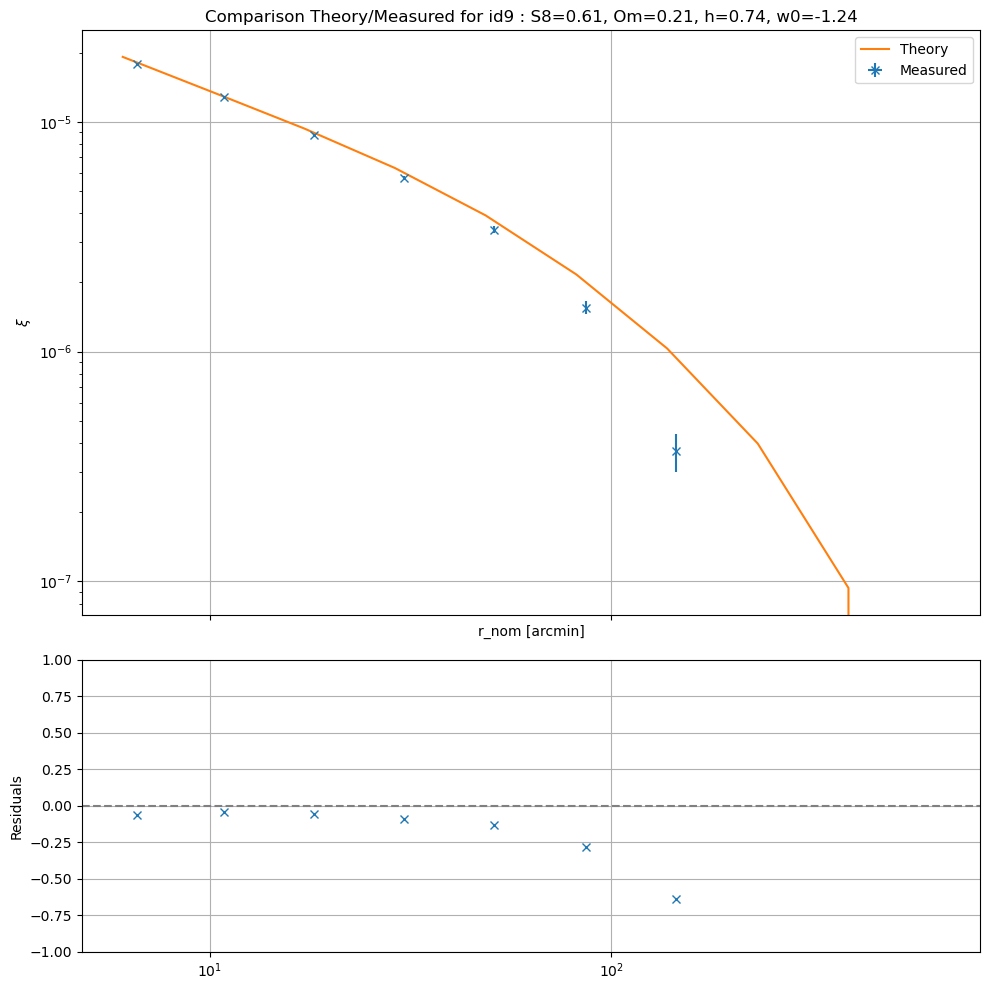

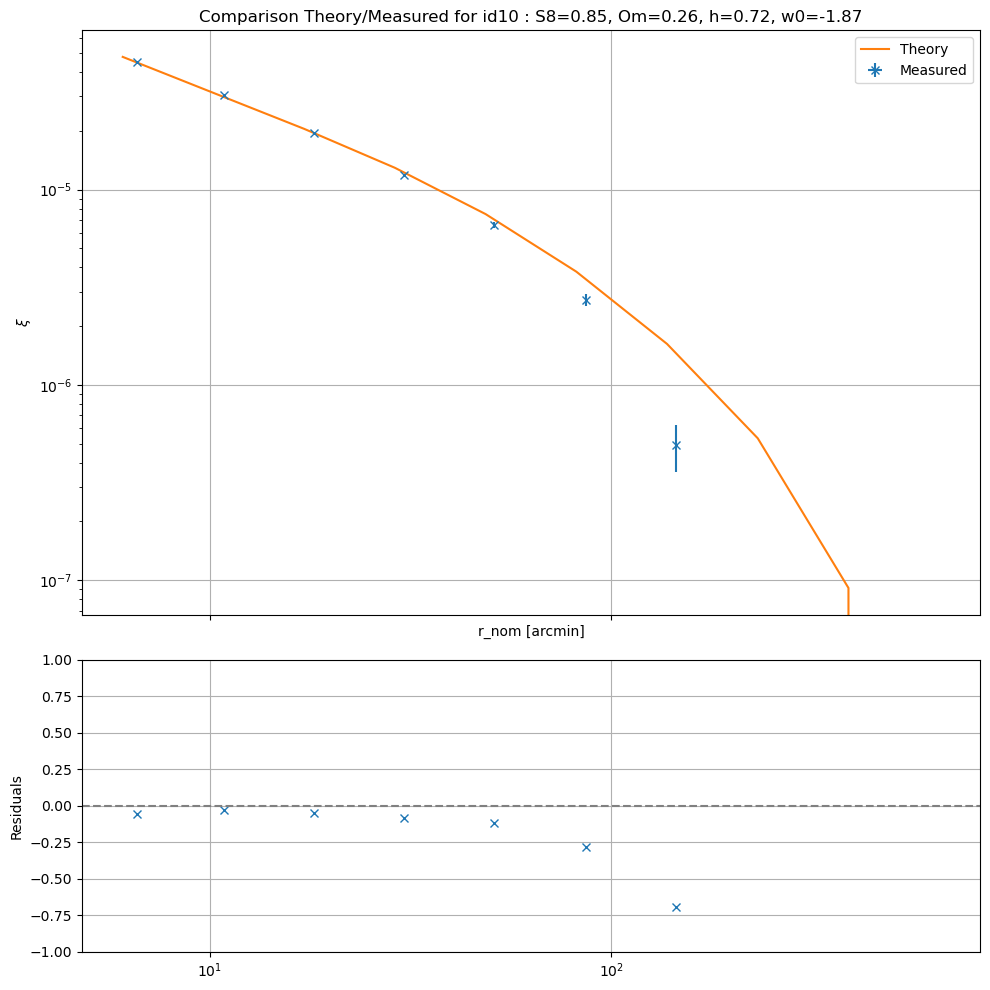

567.199999999999
567.199999999999
567.199999999999
567.199999999999
567.199999999999


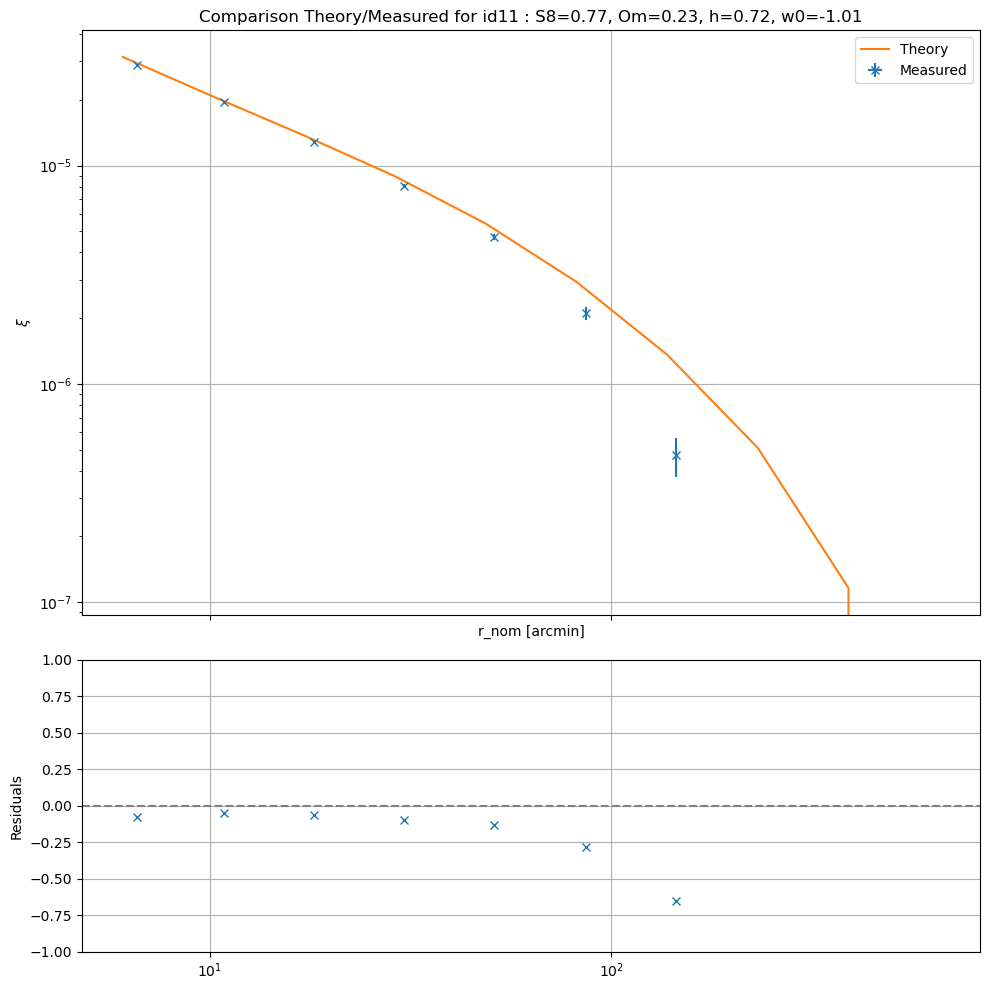

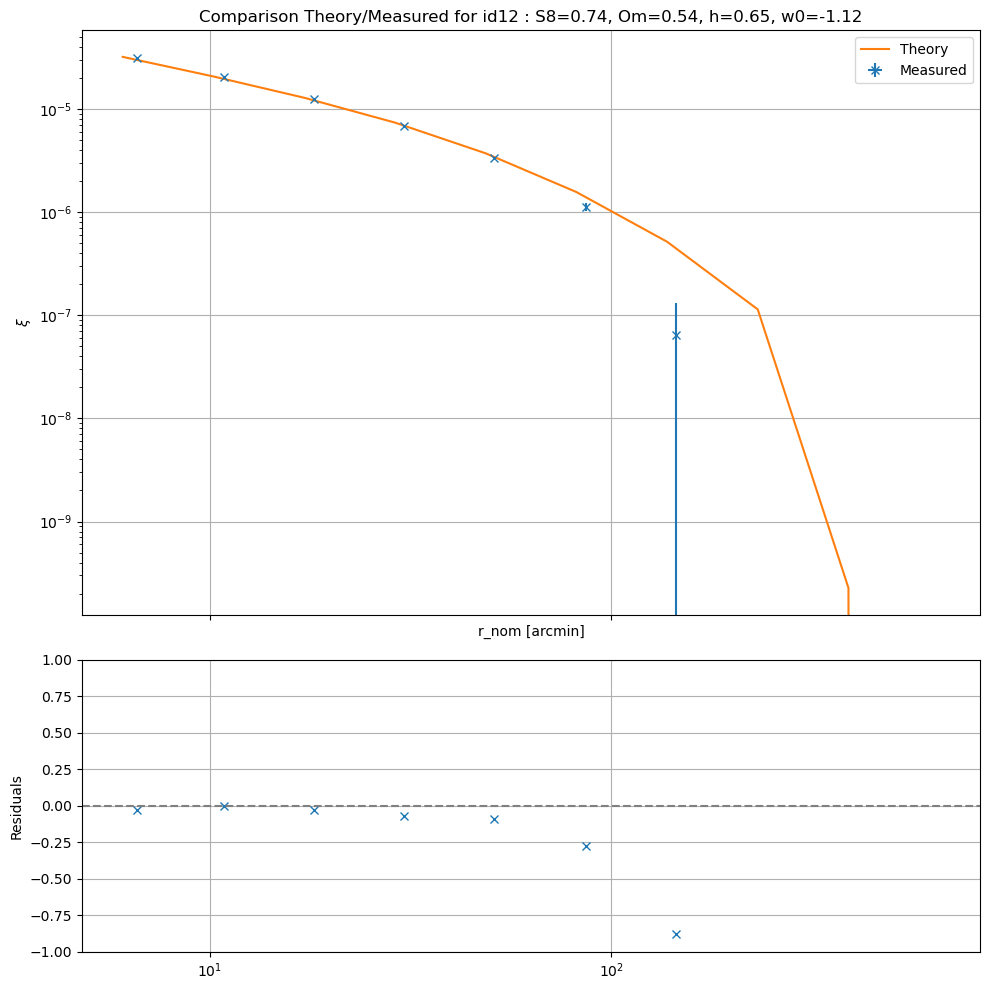

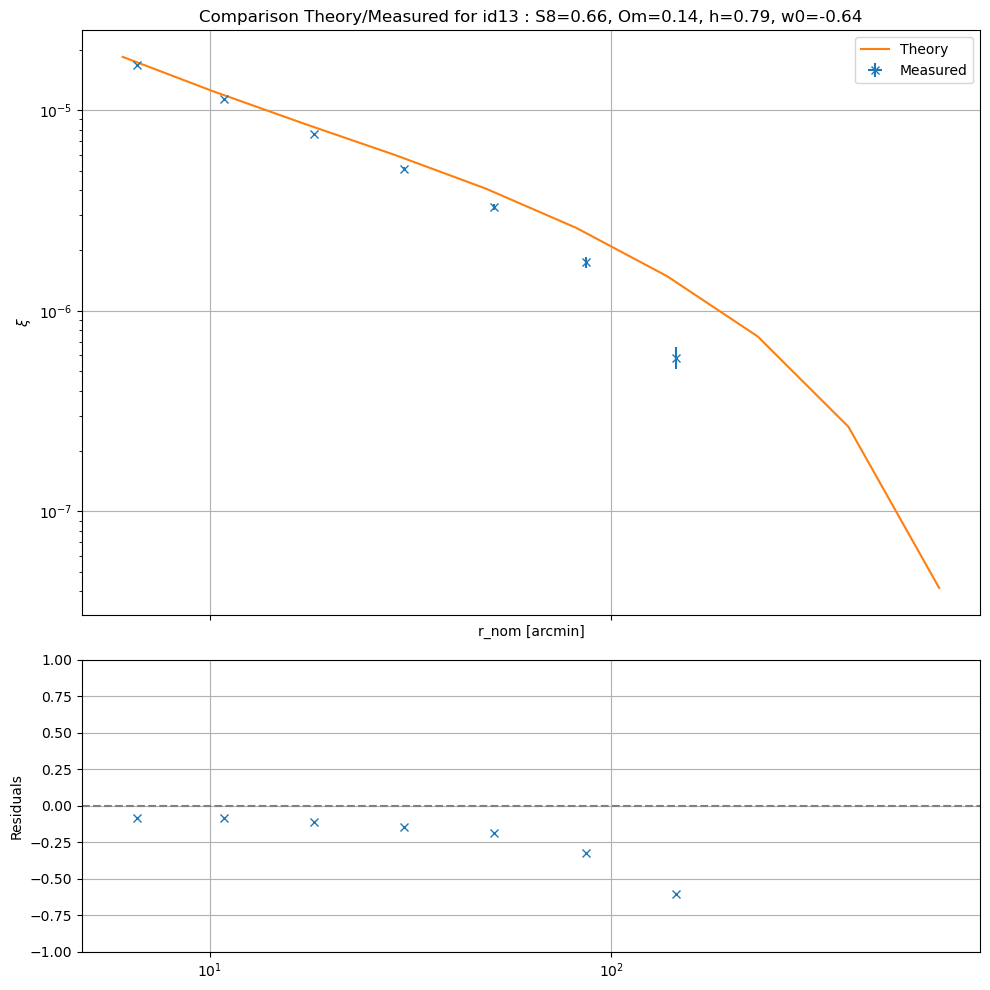

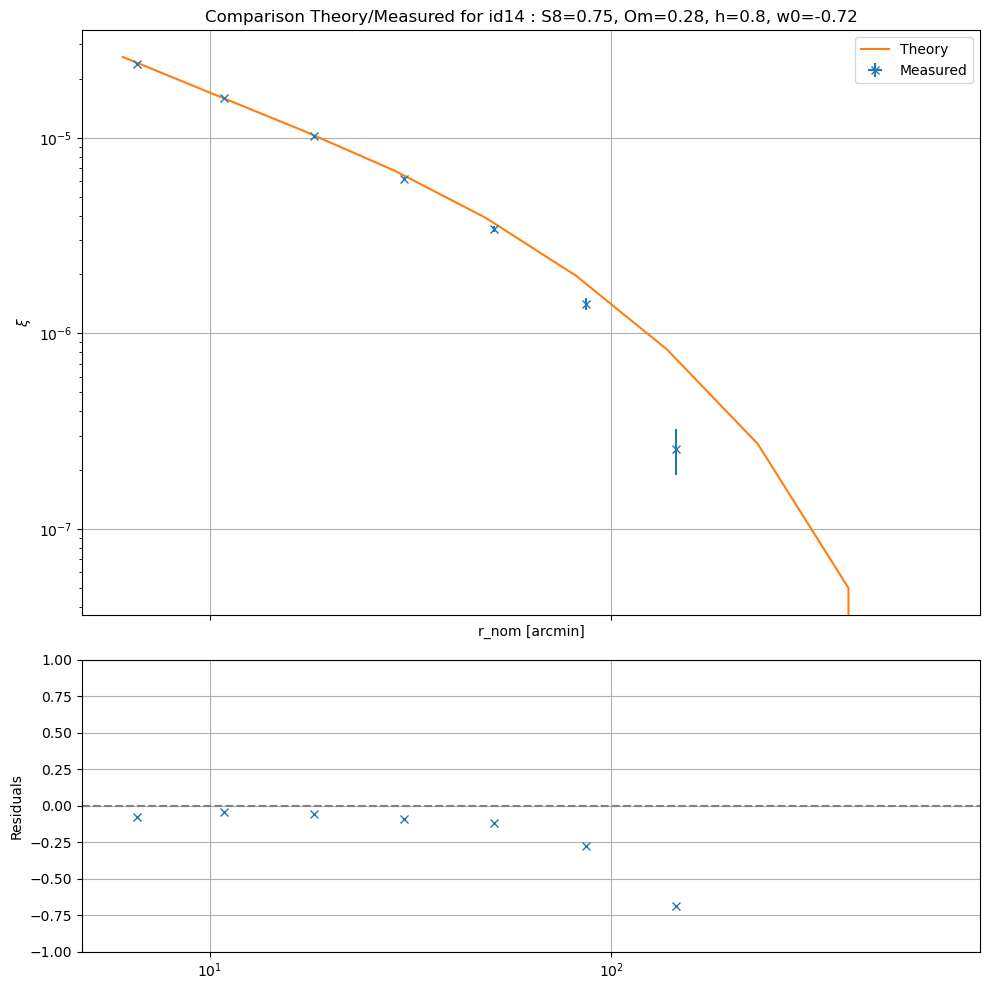

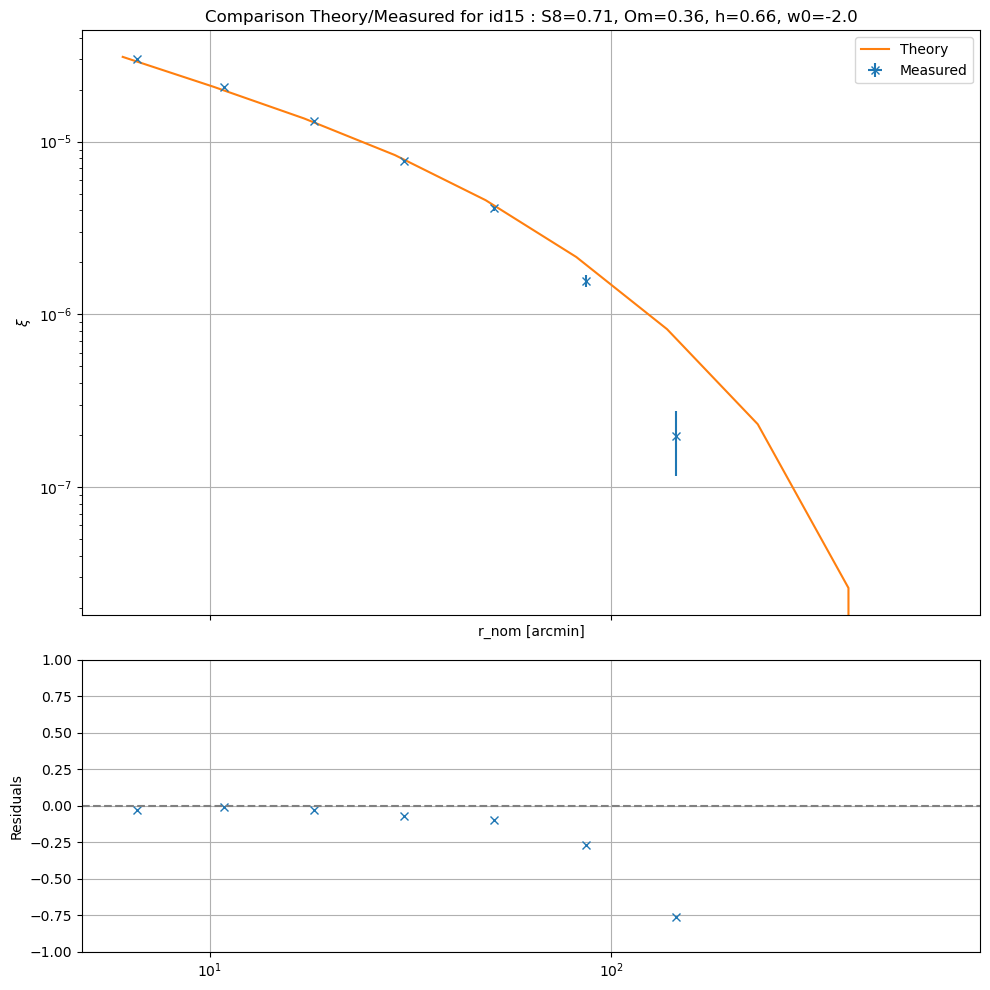

567.199999999999
567.199999999999
567.199999999999
567.199999999999
567.199999999999


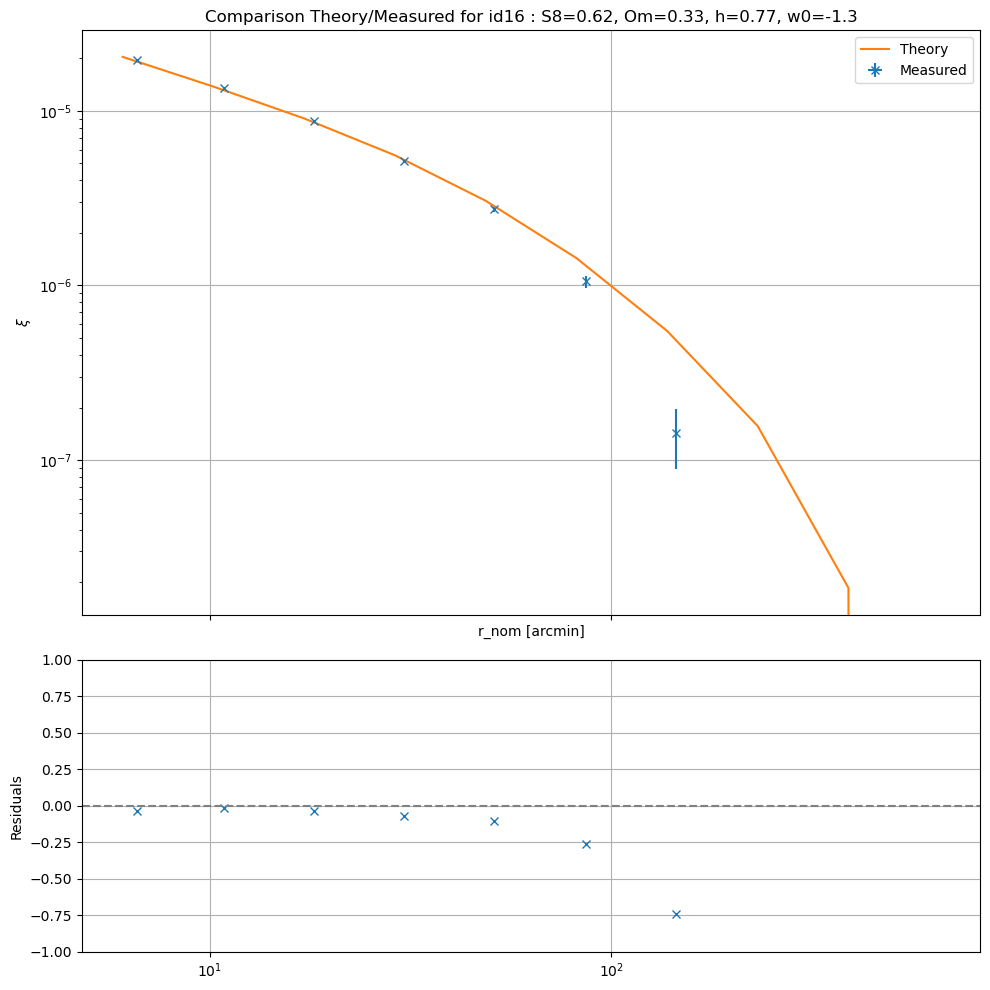

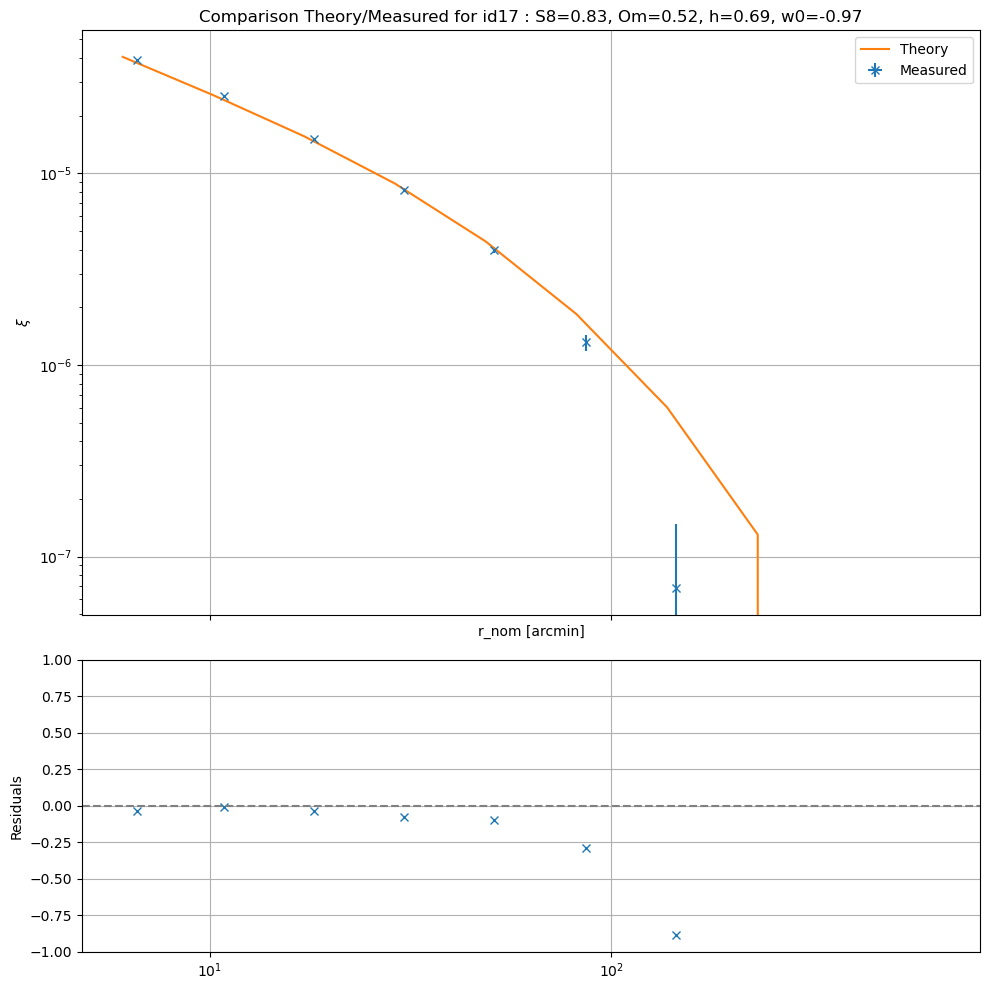

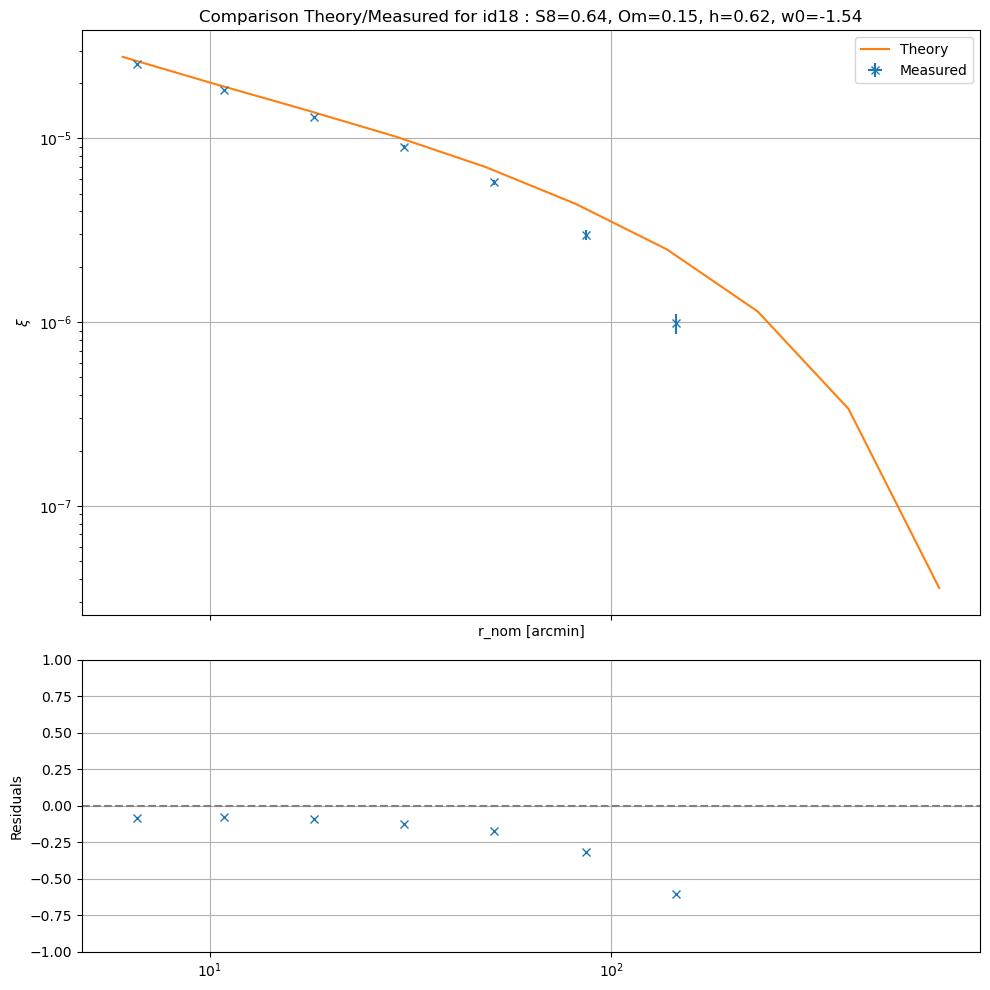

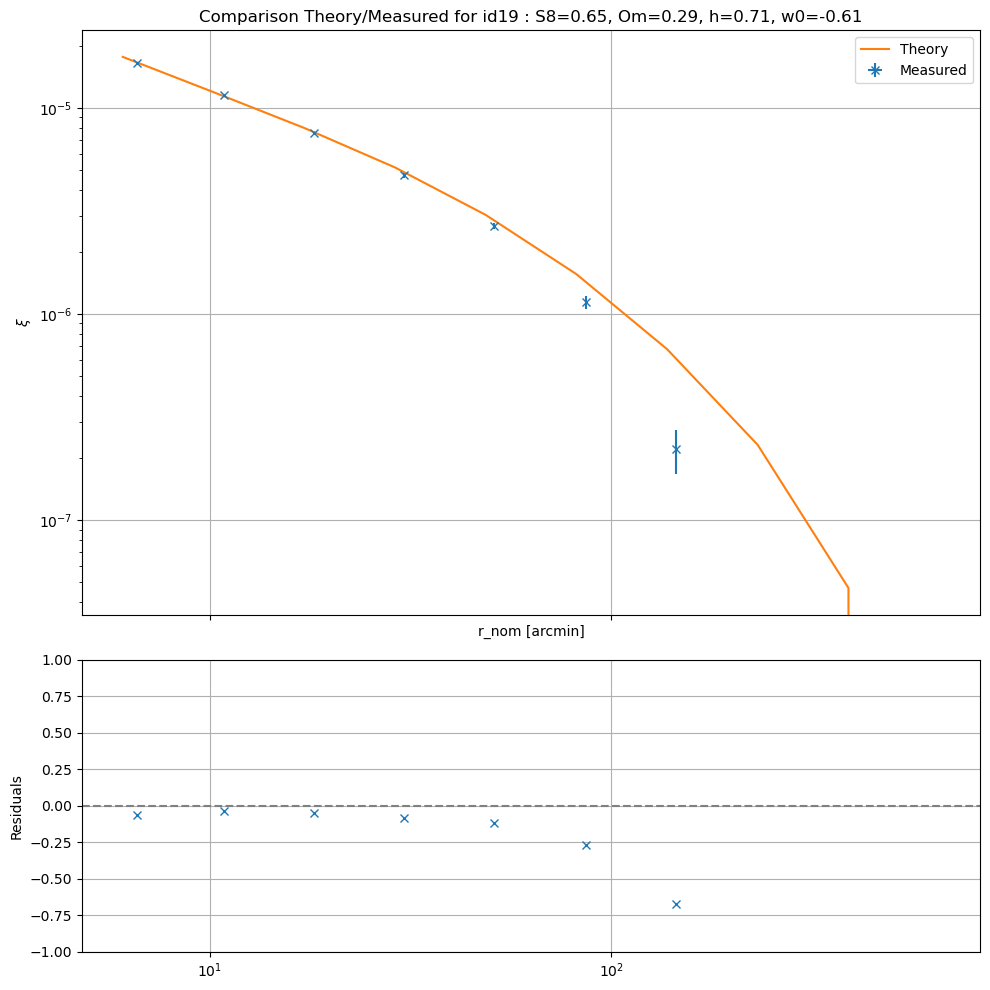

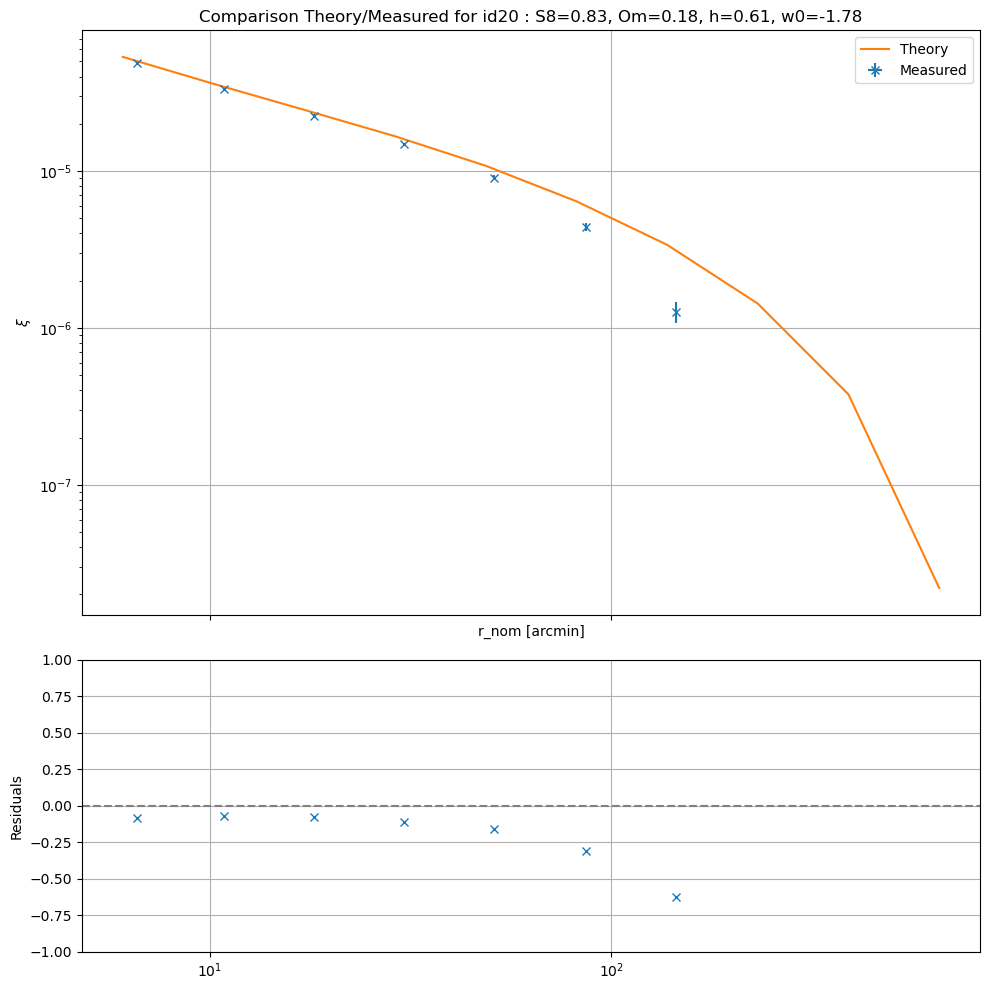

567.199999999999
567.199999999999
567.199999999999
567.199999999999


IndexError: single positional indexer is out-of-bounds

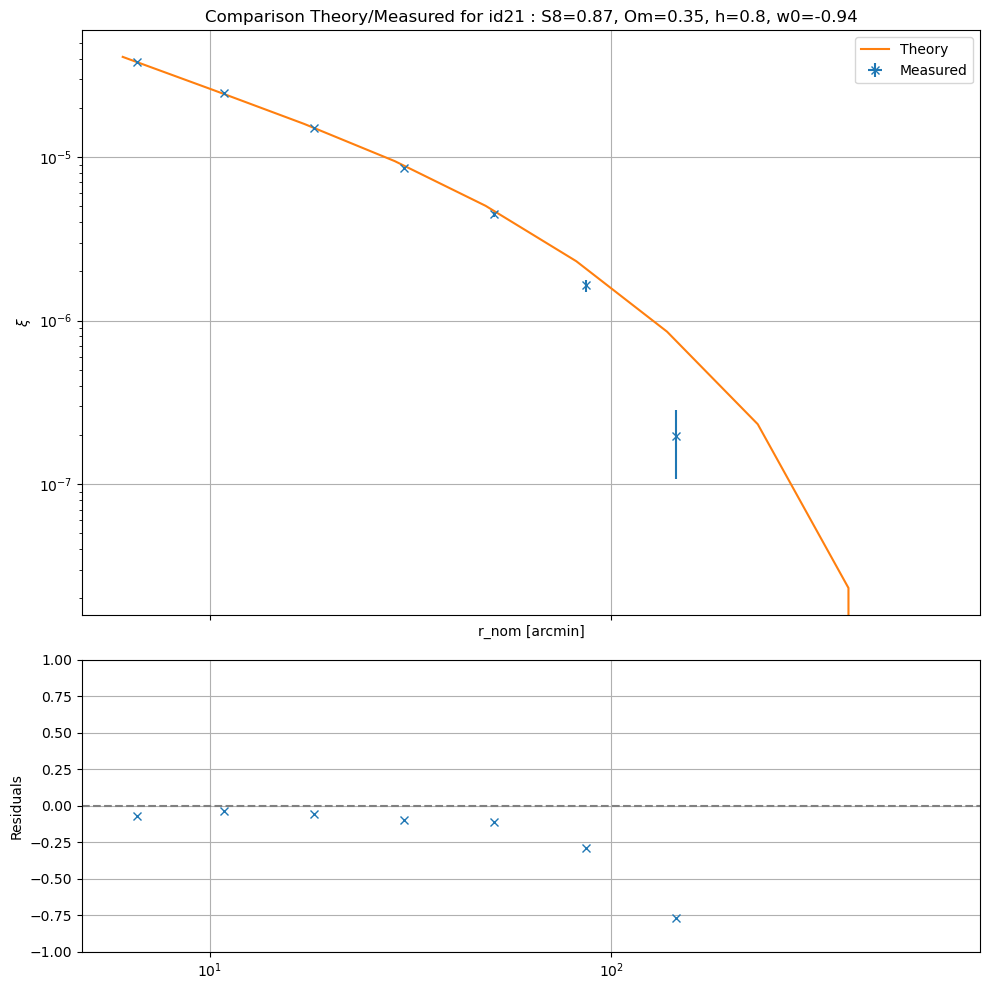

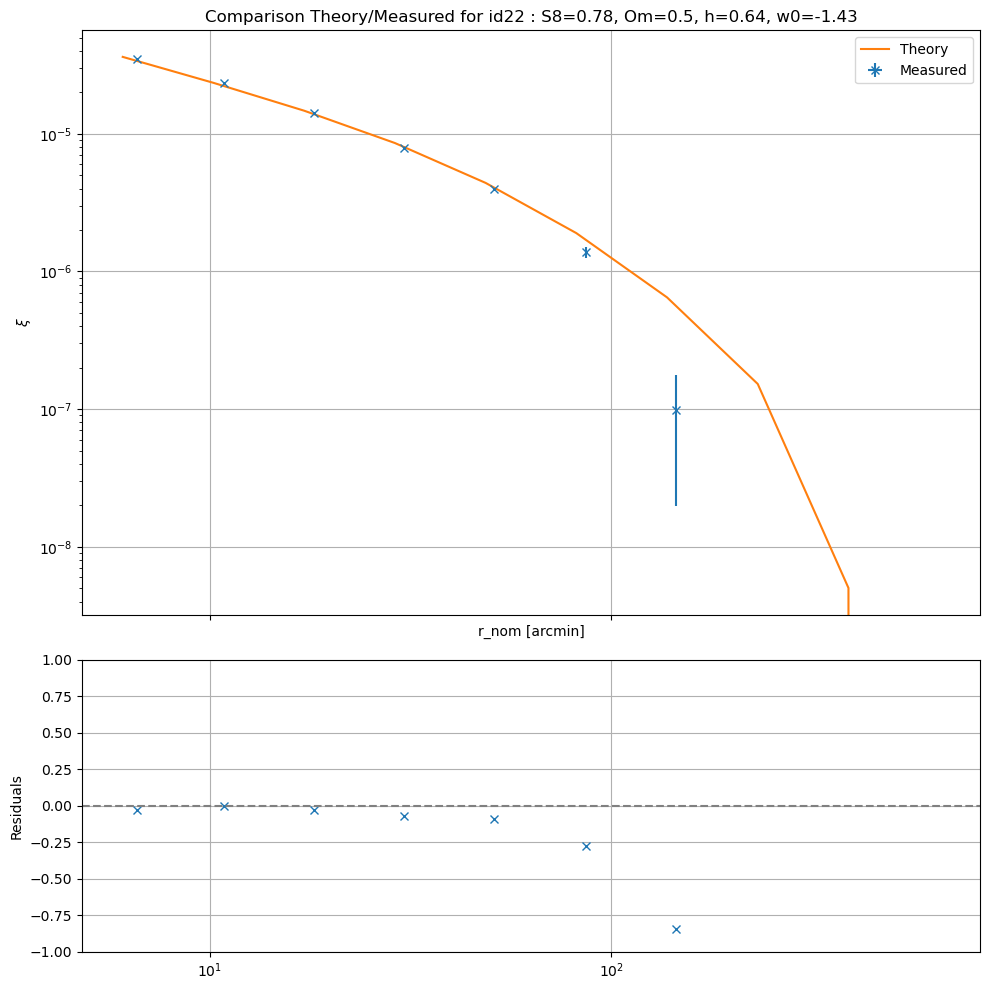

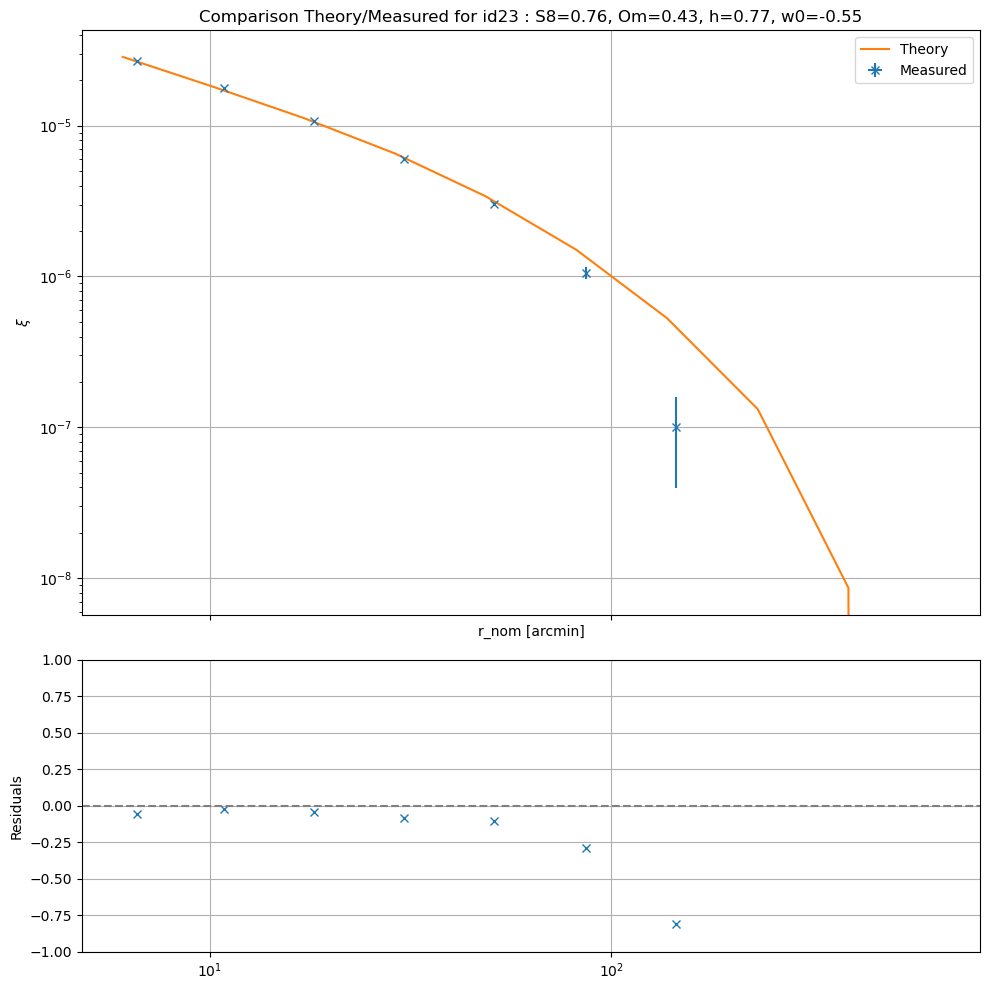

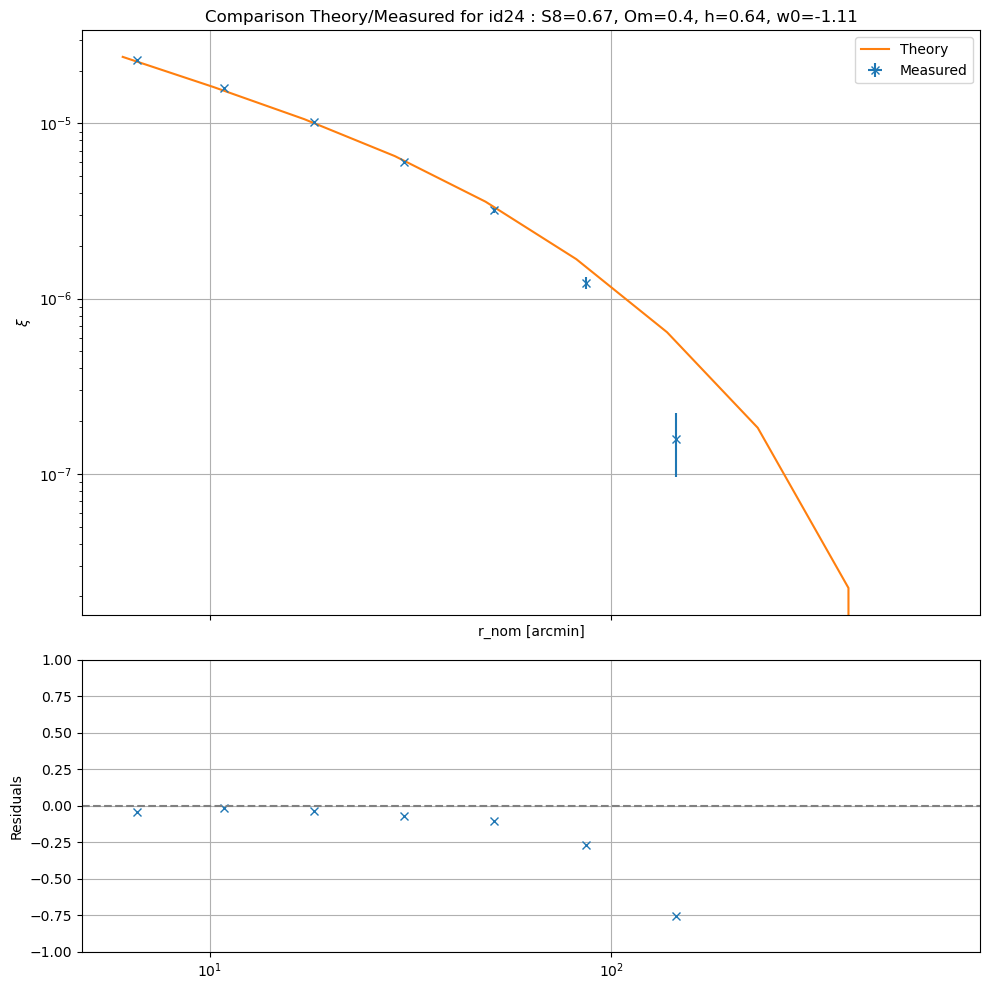

In [8]:
# Path to files
measured_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_LHS_25/measured'
theory_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_LHS_25/theory_2pcf'
seeds = [0]

# Load files
measured_file_names = glob.glob(f"{measured_files_path}/id*.txt")
measured_file_names = sorted([f for f in measured_file_names if any(f"seed{seed}_" in f for seed in seeds)])
measured_files_txt = [np.loadtxt(file) for file in measured_file_names]

theory_file_names = sorted(glob.glob(f"{theory_files_path}/id*.dat"))
theory_files_txt = [np.loadtxt(file) for file in theory_file_names]

params = pd.read_csv('/net/GECO/pisco/SHEAR2COSMO/DBB_LHS_25/lhs_25.csv')

# Create list of measured files, column 4 "xi"
xi_files = []
sxi_files = []
r_files = []
dr_files = []
for i in range(len(measured_files_txt)):
    data = measured_files_txt[i]

    xi = [row[3] for row in data]
    xi_files.append(xi)

    sxi = [row[4] for row in data]
    sxi_files.append(sxi)

    r = [row[1] for row in data]
    r_files.append(r)

    dr = [row[1] for row in data]
    dr_files.append(dr)

th_xi_files = []
th_r_files = []

for i in range(len(theory_files_txt)):
    data = theory_files_txt[i]

    r = [row[0] for row in data]
    th_r_files.append(r)

    xi = [row[1] for row in data]
    th_xi_files.append(xi)

xi_files = np.array(xi_files)
sxi_files = np.array(sxi_files)
r_files = np.array(r_files)
dr_files = np.array(dr_files)
th_xi_files = np.array(th_xi_files)
th_r_files = np.array(th_r_files)

print("Seeds : ",seeds)
print("Shape xi_files : ",np.shape(xi_files))
print("Shape sxi_files : ",np.shape(sxi_files))
print("Shape r_files : ",np.shape(r_files))
print("Shape d_files : ",np.shape(dr_files))
print("Shape th_xi_files : ",np.shape(th_xi_files))
print("Shape th_r_files : ",np.shape(th_r_files))

n_maps = 104
id_cosmo = 0
begin_map = id_cosmo*n_maps
end_map = id_cosmo*n_maps + n_maps
print(begin_map)
print(end_map)

mean_xi = np.mean(xi_files[begin_map:end_map], axis=0)
mean_sxi = np.sqrt(np.sum(sxi_files[begin_map:end_map]**2, axis=0)) / n_maps
mean_r = np.mean(r_files[begin_map:end_map], axis=0)
mean_dr = np.sqrt(np.sum(dr_files[begin_map:end_map]**2, axis=0)) / n_maps

for i in range(26):
    n_maps = 104
    id_cosmo = i
    begin_map = id_cosmo * n_maps
    end_map = id_cosmo * n_maps + n_maps

    #print cosmologies
    params_list = params.iloc[id_cosmo]
    Om = params_list['Om']
    S8 = params_list['S8']
    h = params_list['h']
    w0 = params_list['w0']

    mean_xi = np.mean(xi_files[begin_map:end_map], axis=0)
    mean_sxi = np.std(xi_files[begin_map:end_map], axis=0) / np.sqrt(n_maps)
    mean_r = np.mean(r_files[begin_map:end_map], axis=0)
    mean_dr = np.std(r_files[begin_map:end_map], axis=0) / np.sqrt(n_maps)

    res = (mean_xi - th_xi_files[id_cosmo]) / th_xi_files[id_cosmo]

    print(np.max(mean_r))

    # Create a figure with two subplots (one above the other)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # Plot the main graph in the first subplot
    ax1.errorbar(mean_r, mean_xi, xerr=mean_dr, yerr=mean_sxi, fmt='x', ls='', label='Measured')
    ax1.plot(th_r_files[id_cosmo], th_xi_files[id_cosmo], label='Theory')
    ax1.legend()
    ax1.set_title('Comparison Theory/Measured for id' + str(id_cosmo) + f' : S8={round(S8,2)}, Om={round(Om,2)}, h={round(h,2)}, w0={round(w0,2)}')
    ax1.set_ylabel(r'$\xi$')
    ax1.set_xlabel('r_nom [arcmin]')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.grid()

    # Plot the residuals in the second subplot
    ax2.plot(mean_r, res, 'x', label='Residuals')
    ax2.axhline(0, color='gray', linestyle='--')
    ax2.set_ylabel('Residuals')
    ax2.set_ylim([-1, 1])
    ax2.set_xscale('symlog')
    ax2.grid()

    # Show the plot
    plt.tight_layout()
    plt.savefig(f'/home/lburon/internship/GLASS/2pcf/25_comparison_2pcf_{id_cosmo}')
    if i%5==0:
        plt.show()

Seeds :  [0]
Shape xi_files :  (2496, 10)
Shape sxi_files :  (2496, 10)
Shape r_files :  (2496, 10)
Shape d_files :  (2496, 10)
Shape th_xi_files :  (25, 10)
Shape th_r_files :  (25, 10)
0
104
567.199999999999


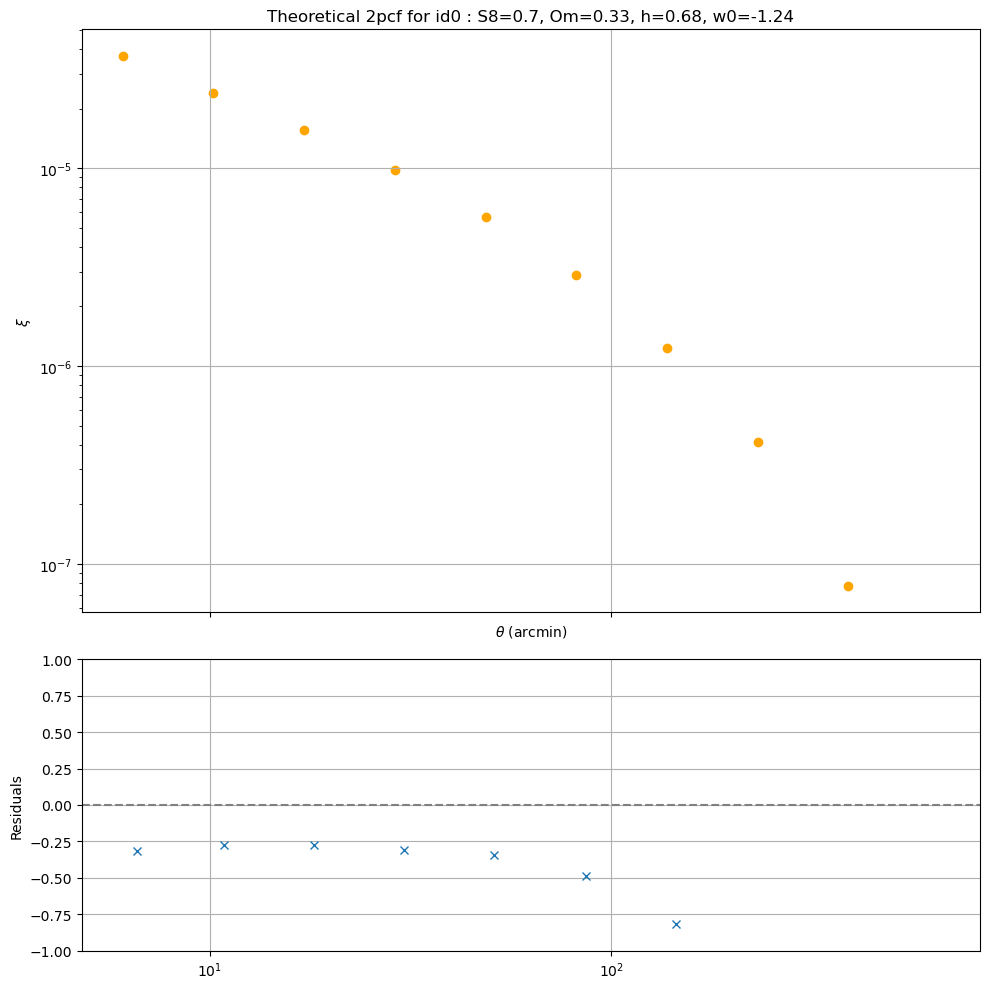

567.199999999999


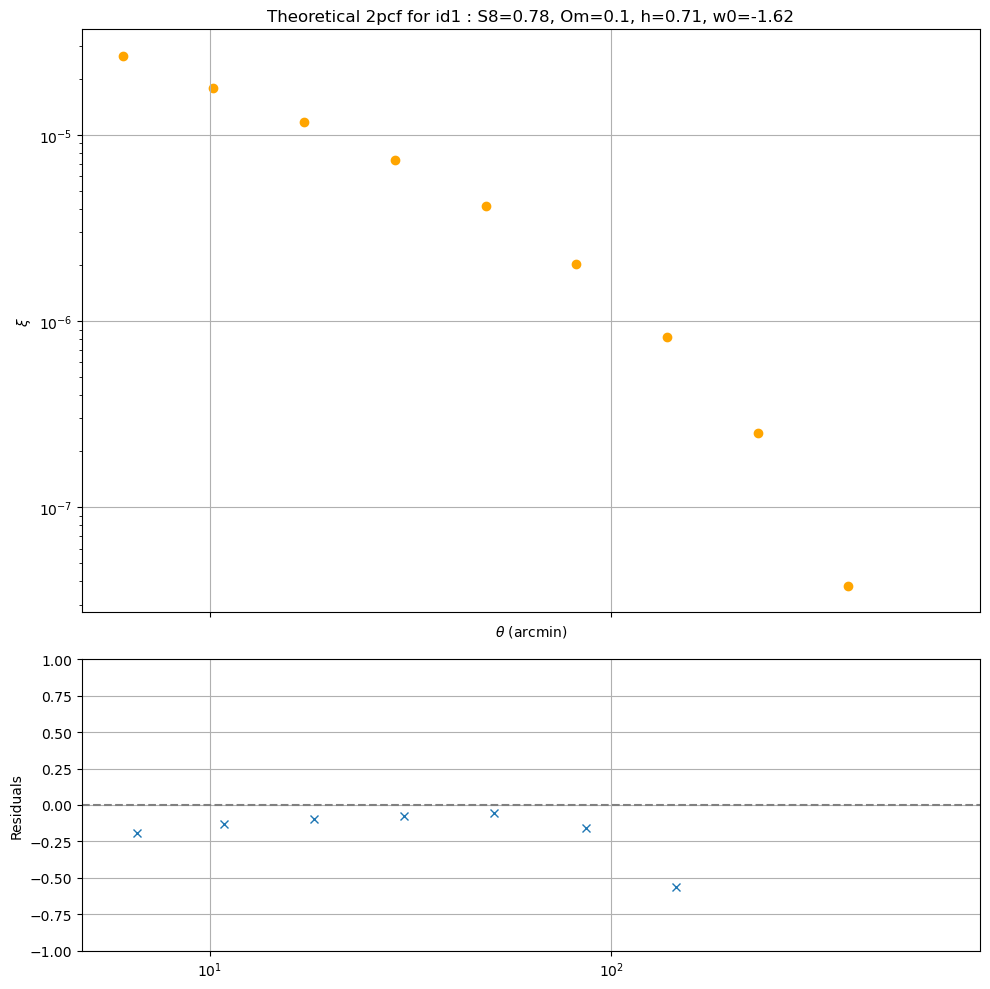

567.199999999999


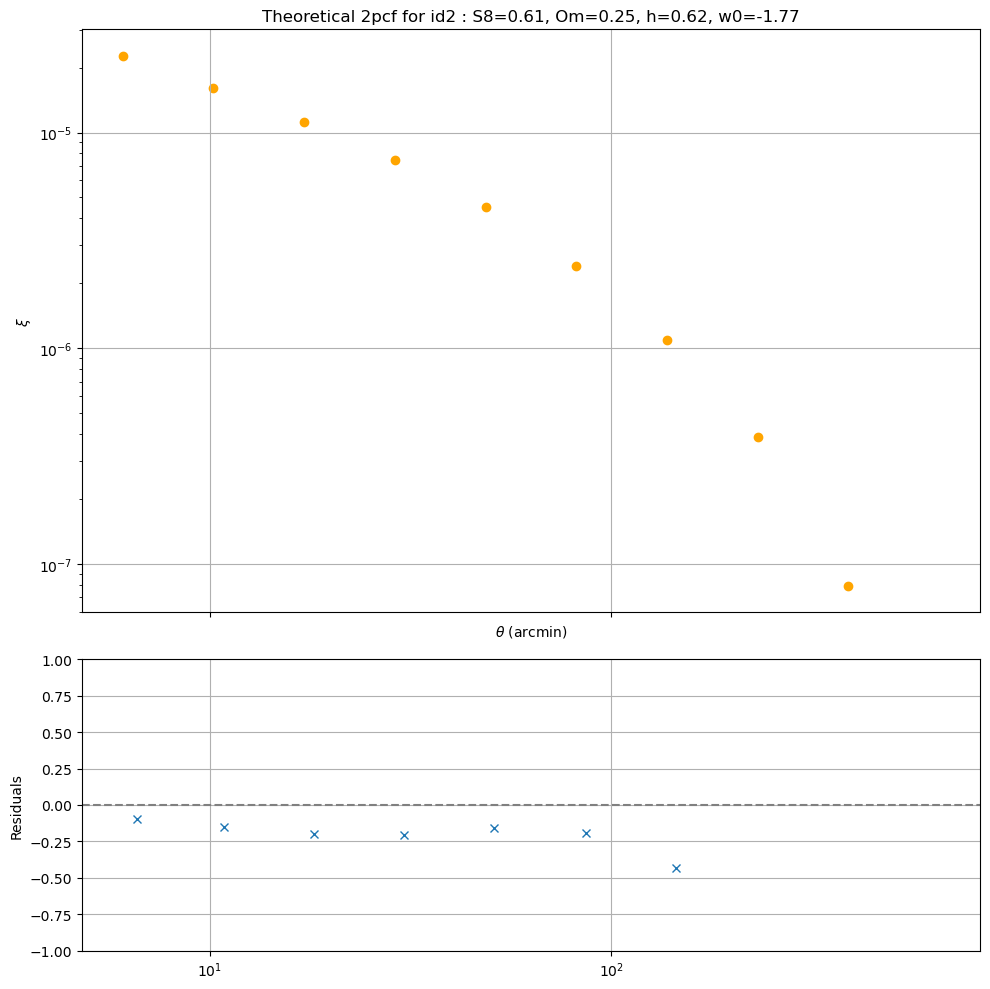

567.199999999999


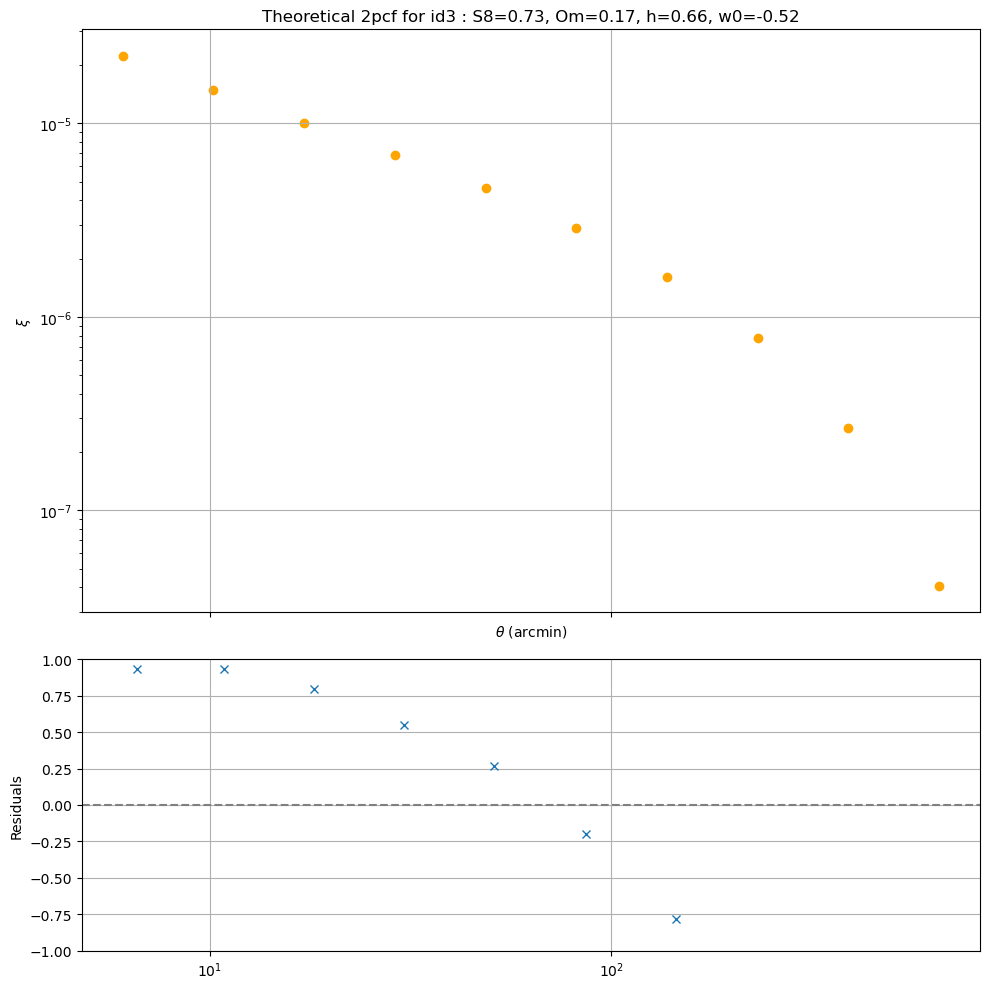

567.199999999999


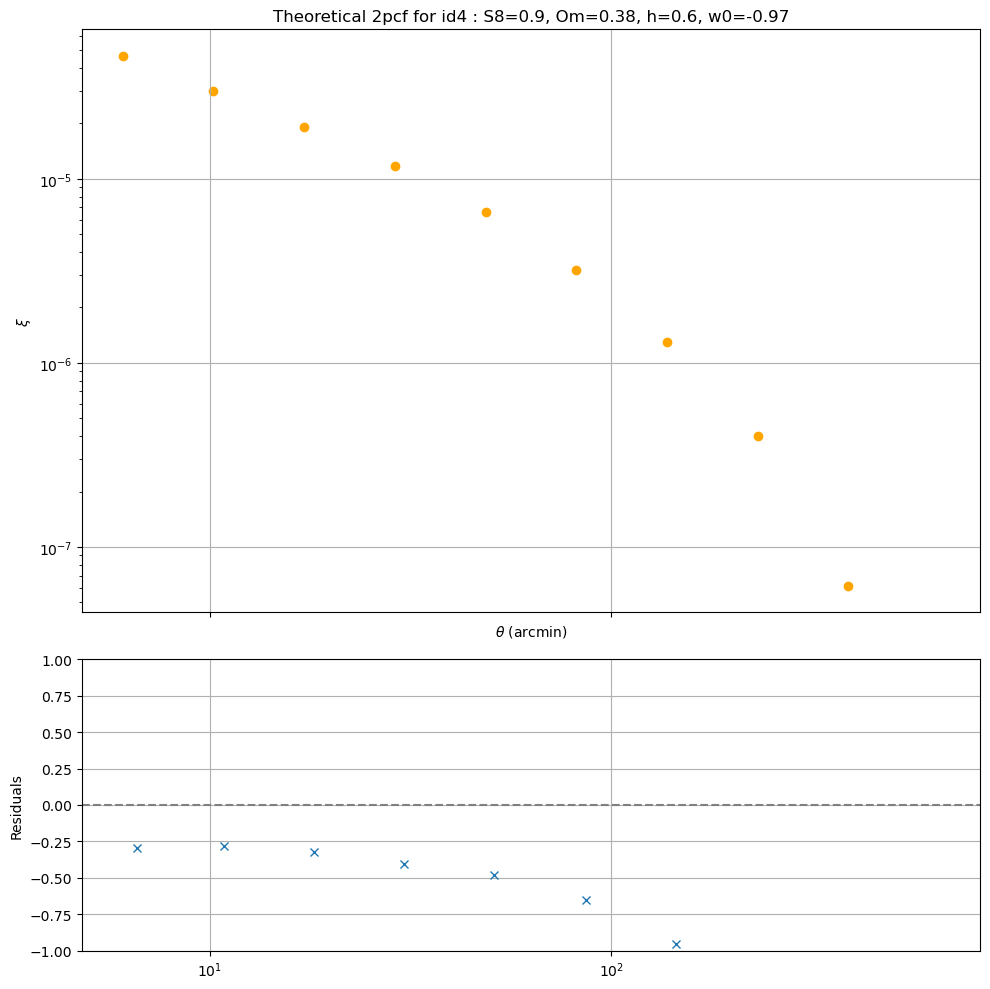

567.199999999999


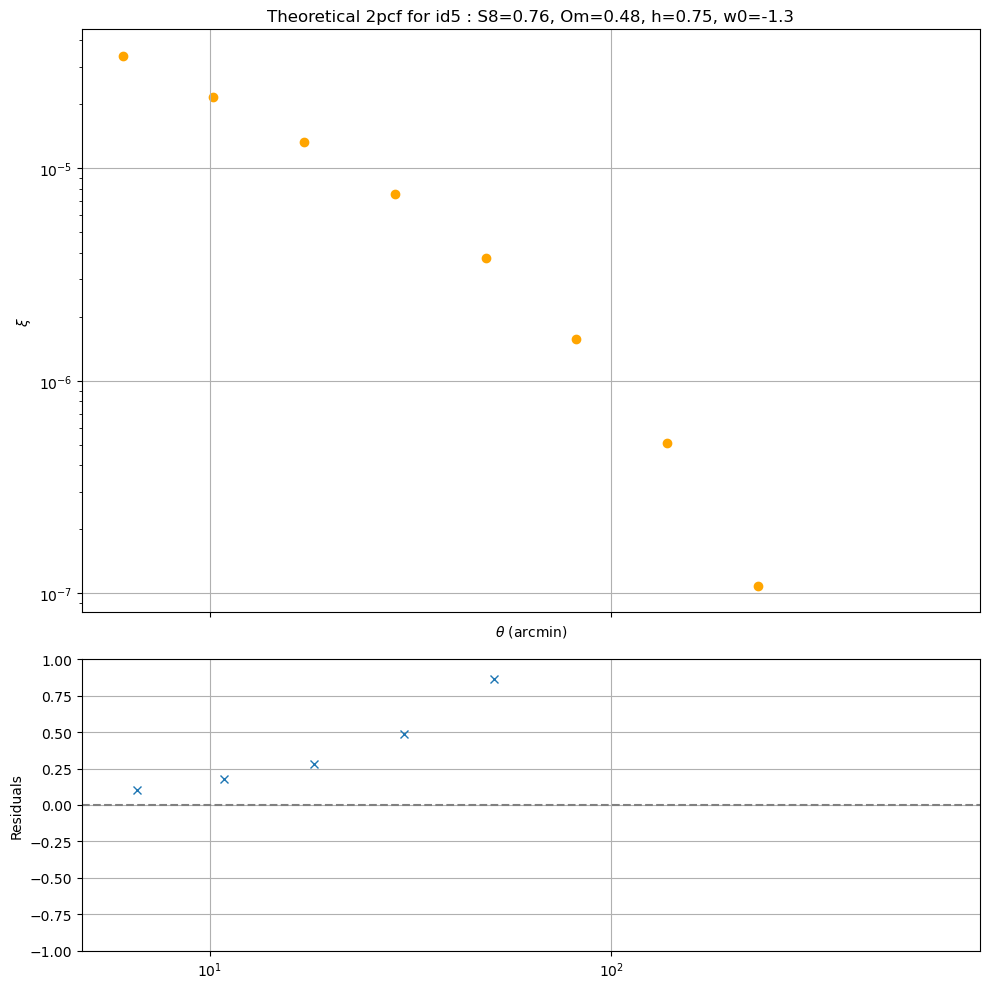

567.199999999999


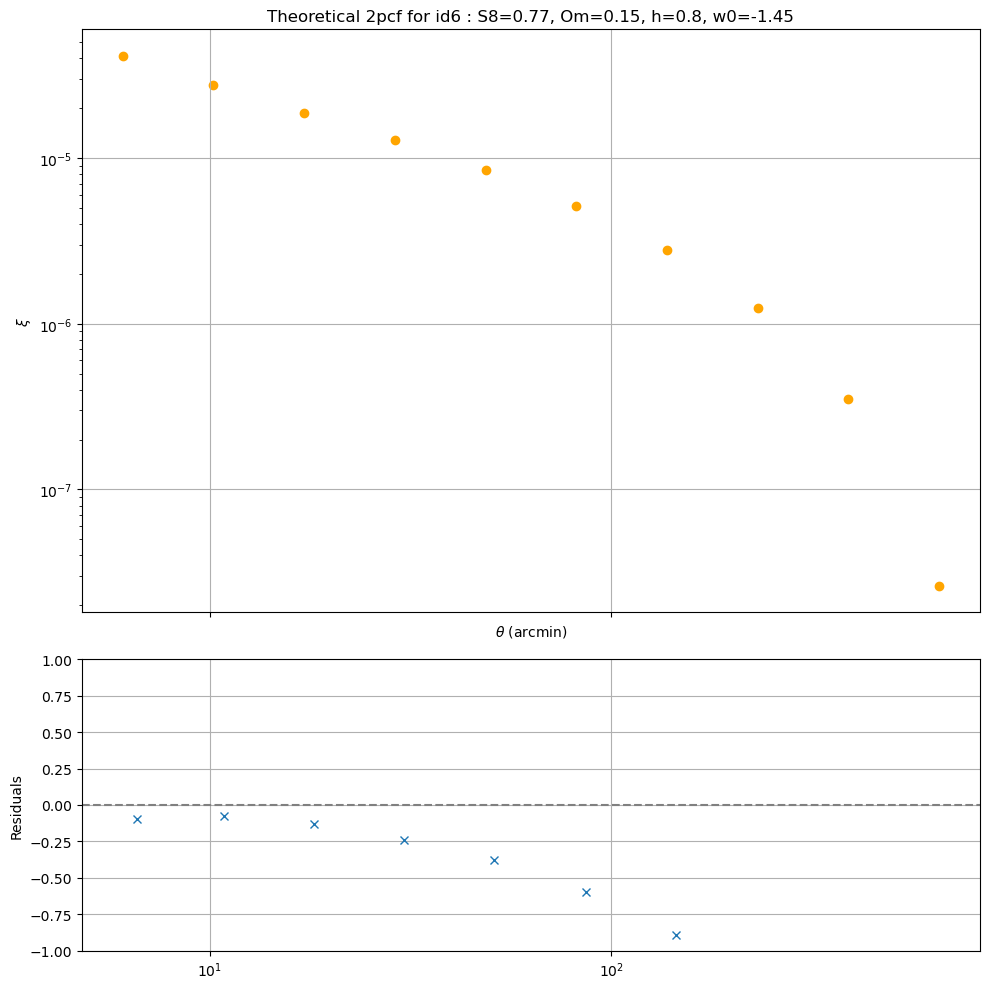

567.199999999999


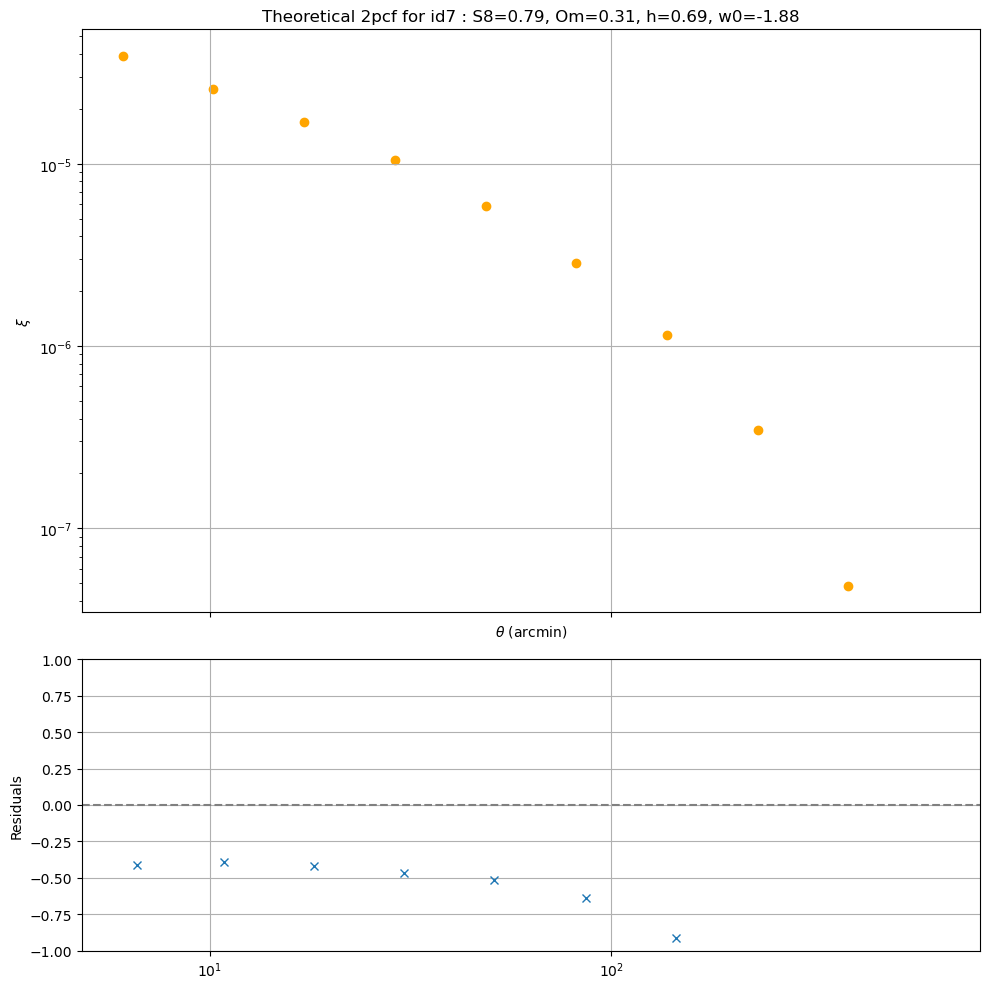

567.199999999999


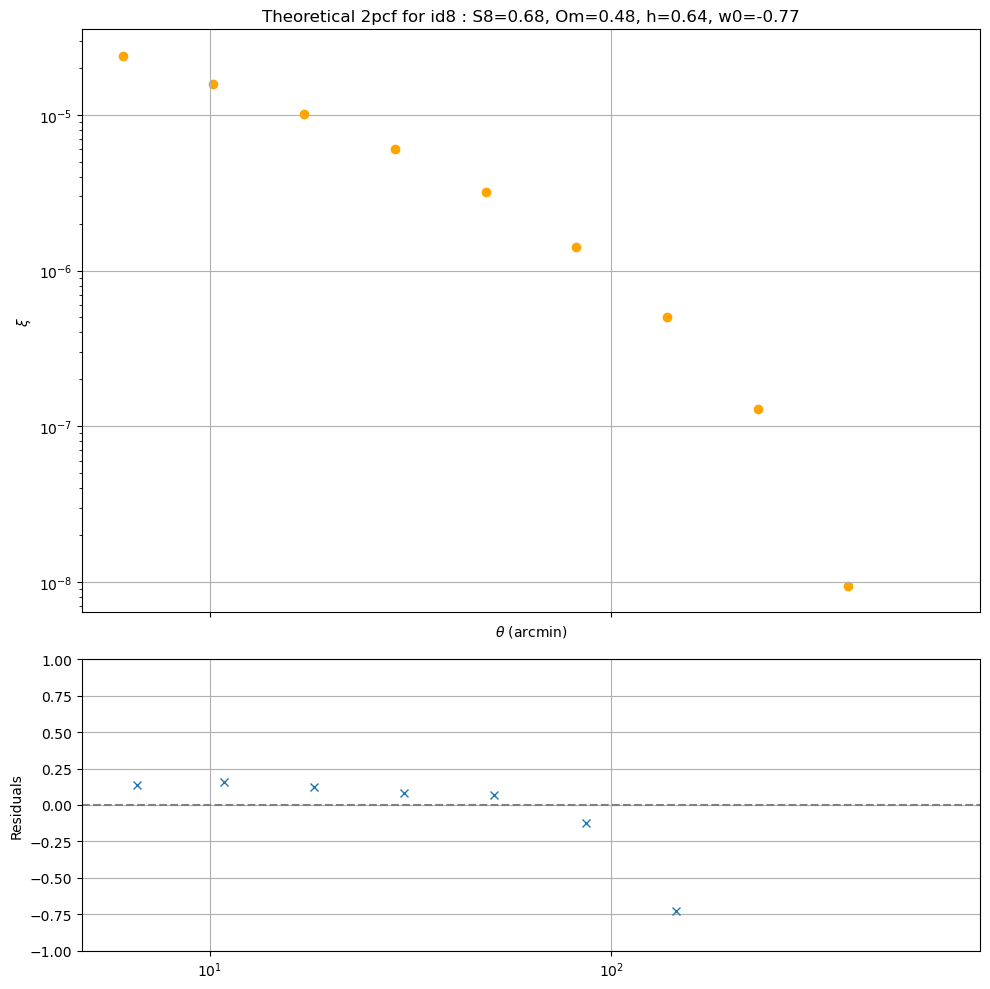

567.199999999999


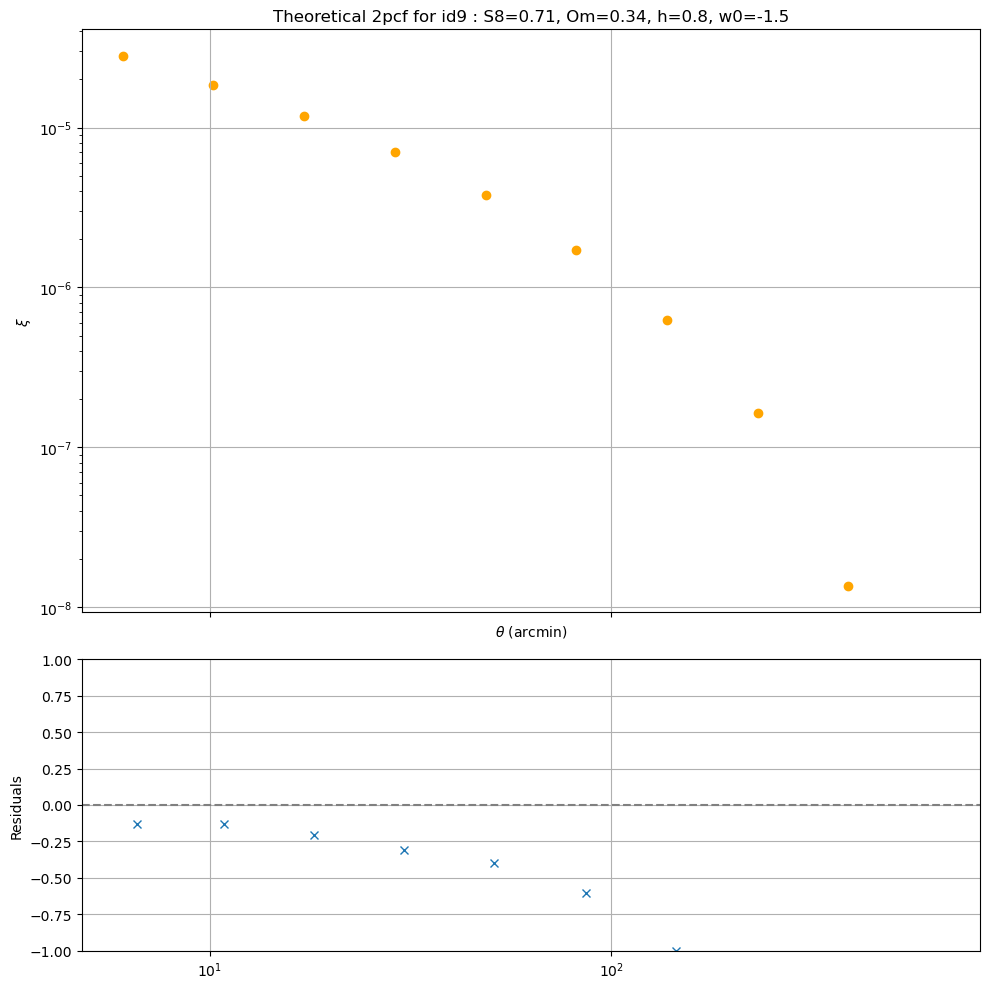

In [4]:
# Path to files
measured_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/measured'
theory_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/theory_2pcf'
seeds = [0]

# Load files
measured_file_names = glob.glob(f"{measured_files_path}/id*.txt")
measured_file_names = sorted([f for f in measured_file_names if any(f"seed{seed}_" in f for seed in seeds)])
measured_files_txt = [np.loadtxt(file) for file in measured_file_names]

theory_file_names = sorted(glob.glob(f"{theory_files_path}/id*.dat"))
theory_files_txt = [np.loadtxt(file) for file in theory_file_names]

params = pd.read_csv('/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/cosmo_slics_table_full.csv')

# Create list of measured files, column 4 "xi"
xi_files = []
sxi_files = []
r_files = []
dr_files = []
for i in range(len(measured_files_txt)):
    data = measured_files_txt[i]

    xi = [row[3] for row in data]
    xi_files.append(xi)

    sxi = [row[4] for row in data]
    sxi_files.append(sxi)

    r = [row[1] for row in data]
    r_files.append(r)

    dr = [row[1] for row in data]
    dr_files.append(dr)

th_xi_files = []
th_r_files = []

for i in range(len(theory_files_txt)):
    data = theory_files_txt[i]

    r = [row[0] for row in data]
    th_r_files.append(r)

    xi = [row[1] for row in data]
    th_xi_files.append(xi)

xi_files = np.array(xi_files)
sxi_files = np.array(sxi_files)
r_files = np.array(r_files)
dr_files = np.array(dr_files)
th_xi_files = np.array(th_xi_files)
th_r_files = np.array(th_r_files)

print("Seeds : ",seeds)
print("Shape xi_files : ",np.shape(xi_files))
print("Shape sxi_files : ",np.shape(sxi_files))
print("Shape r_files : ",np.shape(r_files))
print("Shape d_files : ",np.shape(dr_files))
print("Shape th_xi_files : ",np.shape(th_xi_files))
print("Shape th_r_files : ",np.shape(th_r_files))

n_maps = 104
id_cosmo = 0
begin_map = id_cosmo*n_maps
end_map = id_cosmo*n_maps + n_maps
print(begin_map)
print(end_map)

mean_xi = np.mean(xi_files[begin_map:end_map], axis=0)
mean_sxi = np.sqrt(np.sum(sxi_files[begin_map:end_map]**2, axis=0)) / n_maps
mean_r = np.mean(r_files[begin_map:end_map], axis=0)
mean_dr = np.sqrt(np.sum(dr_files[begin_map:end_map]**2, axis=0)) / n_maps

for i in range(10):
    n_maps = 104
    id_cosmo = i
    begin_map = id_cosmo * n_maps
    end_map = id_cosmo * n_maps + n_maps

    #print cosmologies
    params_list = params.iloc[id_cosmo]
    Om = params_list['Om']
    S8 = params_list['S8']
    h = params_list['h']
    w0 = params_list['w0']

    mean_xi = np.mean(xi_files[begin_map:end_map], axis=0)
    mean_sxi = np.std(xi_files[begin_map:end_map], axis=0) / np.sqrt(n_maps)
    mean_r = np.mean(r_files[begin_map:end_map], axis=0)
    mean_dr = np.std(r_files[begin_map:end_map], axis=0) / np.sqrt(n_maps)

    res = (mean_xi - th_xi_files[id_cosmo]) / th_xi_files[id_cosmo]

    print(np.max(mean_r))

    # Create a figure with two subplots (one above the other)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # Plot the main graph in the first subplot
    #ax1.errorbar(th_r_files[id_cosmo], mean_xi, xerr=mean_dr, yerr=mean_sxi, fmt='x', ls='', label='Measured')
    ax1.scatter(th_r_files[id_cosmo], th_xi_files[id_cosmo], label='Theory',color='orange')
    #ax1.legend()
    ax1.set_title('Theoretical 2pcf for id' + str(id_cosmo) + f' : S8={round(S8,2)}, Om={round(Om,2)}, h={round(h,2)}, w0={round(w0,2)}')
    ax1.set_ylabel(r'$\xi$')
    ax1.set_xlabel(r'$\theta$ (arcmin)')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.grid()

    # Plot the residuals in the second subplot
    ax2.plot(mean_r, res, 'x', label='Residuals')
    ax2.axhline(0, color='gray', linestyle='--')
    ax2.set_ylabel('Residuals')
    ax2.set_ylim([-1, 1])
    ax2.set_xscale('symlog')
    ax2.grid()

    # Show the plot
    plt.tight_layout()
    #plt.savefig(f'/home/lburon/internship/GLASS/2pcf/cosmoslics_log_comparison_2pcf_{id_cosmo}')
    #plt.close(fig)
    plt.show()

[[ 3.69945004e-05  2.39392153e-05  1.55487798e-05  9.79820063e-06
   5.68334618e-06  2.89497612e-06  1.23771185e-06  4.14799270e-07
   7.74844869e-08 -1.12059775e-08]
 [ 2.65349359e-05  1.78045403e-05  1.17613470e-05  7.36184166e-06
   4.15719263e-06  2.02854393e-06  8.17452475e-07  2.51028748e-07
   3.78752522e-08 -1.12598397e-08]
 [ 2.26889857e-05  1.60725829e-05  1.12024038e-05  7.43052877e-06
   4.49913972e-06  2.39643475e-06  1.08844087e-06  3.87331094e-07
   7.90069252e-08 -6.05970137e-09]
 [ 2.23527983e-05  1.48206021e-05  1.00580277e-05  6.90491343e-06
   4.60984376e-06  2.86827567e-06  1.60368970e-06  7.76081635e-07
   2.66396012e-07  4.07682740e-08]
 [ 4.65570813e-05  2.98346583e-05  1.90718976e-05  1.17307450e-05
   6.58089401e-06  3.20972635e-06  1.29545584e-06  3.98725776e-07
   6.15573862e-08 -1.71611604e-08]
 [ 3.37759647e-05  2.15760937e-05  1.32830631e-05  7.55345443e-06
   3.76396172e-06  1.56701791e-06  5.08102397e-07  1.08627023e-07
  -1.97441874e-09 -1.49919267e-08